# Pindel indel-sensitivity benchmark — results

Results from `results/expt{A,B,C,D}/<dataset>/`. Datasets: `tla` (400 bp synthetic) and `LAGA_LC` (711 bp real amplicon).

- **A** — sensitivity grid: detection vs indel *length* × *allele fraction*, across read length, depth, dataset. Scored at the `-e 1` ceiling.
- **B** — positional blind spots: detection vs breakpoint position, per read length.
- **C** — support-threshold sweep: post-hoc re-score of A's VCFs to pick `pindel2vcf -e`, plus the AD-vs-true-AF gap.
- **D** — caller comparison: Pindel vs VarScan2 vs Mutect2 vs LoFreq on the same BAMs.

## Key findings (August 2026 — all experiments complete)

| Caller | tla F1 | LAGA_LC F1 | Notes |
|---|---|---|---|
| **LoFreq** | **0.73** | **0.74** | Consistent across amplicons — recommended |
| Pindel (`ad_frac ≥ 1%`) | 0.66 | 0.35 | Degrades on LAGA_LC; requires per-amplicon `-i` calibration |
| Mutect2 | 0.47 | 0.50 | High floor (~20% AF); near-zero at 1–5% AF |
| VarScan2 | 0.54 | 0.40 | High sensitivity, low precision (noisy) |

**Recommendation:** couple LoFreq into the production amplicon pipeline alongside or instead of Pindel.
Pindel's insert size (`-i`) cannot be derived from first principles for amplicons — it must be calibrated
empirically per amplicon, and getting it wrong zeroes LAGA_LC detection entirely.
See [results/findings.md](results/findings.md) for full analysis.


## Setup

In [17]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 10

# Benchmark root — adjust if running from a different working directory.
BENCH = Path("runs/sim_benchmark").resolve()
if not BENCH.exists():
    BENCH = Path("/home/robolab/cindy_ren/ngs/expt_summer2026/amp-pip-dev/"
                 "2026-07_pindel_indel_sensitivity/runs/sim_benchmark")

print("Benchmark root:", BENCH)

RESULTS = BENCH.parent.parent / "results"  # results/ alongside runs/ in experiment dir
RESULTS.mkdir(exist_ok=True)
print("Results root:", RESULTS)

def _try_load(path, comment=None):
    """Return a DataFrame if the file exists, else None (no error)."""
    p = Path(path)
    return pd.read_csv(p, comment=comment) if p.exists() else None


def load_expt(expt, dataset):
    """Load one experiment's results for one dataset.

    Returns a dict with keys:
      ready  – True only when all required files are present.
      det    – detection_results.csv (all conditions)
      conf   – confusion_metrics.csv
      near   – nearmiss.csv (None if absent)
      pos    – position_sensitivity.csv (Exp B only)
      sweep  – threshold_sweep.csv (Exp C only)
      gap    – af_gap.csv (Exp C only)
      mut    – mutant-only rows of det, detected cast to float

    Prints a clear status line so you can see what is missing.
    """
    base = RESULTS / f"expt{expt}" / dataset
    required = {
        "A": ["detection_results.csv", "confusion_metrics.csv"],
        "B": ["detection_results.csv", "confusion_metrics.csv"],
        "C": ["threshold_sweep.csv", "af_gap.csv"],
    }.get(expt, [])

    missing = [f for f in required if not (base / f).exists()]
    if missing:
        print(f"[Exp {expt}/{dataset}] NOT READY — missing: {missing}")
        return {"ready": False}

    det   = _try_load(base / "detection_results.csv")
    conf  = _try_load(base / "confusion_metrics.csv")
    near  = _try_load(base / "nearmiss.csv")
    pos   = _try_load(base / "position_sensitivity.csv", comment="#")
    sweep = _try_load(base / "threshold_sweep.csv")
    gap   = _try_load(base / "af_gap.csv")

    mut = None
    if det is not None:
        mut = det[det["is_control"] == 0].copy()
        mut["detected"] = pd.to_numeric(mut["detected"], errors="coerce")

    n_mut = len(mut) if mut is not None else 0
    print(f"[Exp {expt}/{dataset}] READY — {n_mut} mutant conditions")
    return {"ready": True, "det": det, "conf": conf, "near": near,
            "pos": pos, "sweep": sweep, "gap": gap, "mut": mut}


Benchmark root: /home/robolab/cindy_ren/ngs/expt_summer2026/amp-pip-dev/2026-07_pindel_indel_sensitivity/runs/sim_benchmark
Results root: /home/robolab/cindy_ren/ngs/expt_summer2026/amp-pip-dev/2026-07_pindel_indel_sensitivity/results


In [18]:
def facet_heatmaps(data, value, x, y, facet_row, facet_col, title,
                   vmin=0.0, vmax=1.0, cmap="RdYlGn", agg="mean", fmt="{:.2f}"):
    """Grid of annotated heatmaps: one (y vs x of `value`) per facet_row x facet_col."""
    rows = sorted(data[facet_row].unique())
    cols = sorted(data[facet_col].unique())
    xs = sorted(data[x].unique())
    ys = sorted(data[y].unique())
    norm = Normalize(vmin=vmin, vmax=vmax)
    fig, axes = plt.subplots(len(rows), len(cols),
                             figsize=(2.6 * len(cols) + 1.2, 2.4 * len(rows) + 0.8),
                             squeeze=False)
    im = None
    for i, r in enumerate(rows):
        for j, c in enumerate(cols):
            ax = axes[i][j]
            sub = data[(data[facet_row] == r) & (data[facet_col] == c)]
            piv = sub.pivot_table(index=y, columns=x, values=value, aggfunc=agg)
            piv = piv.reindex(index=ys, columns=xs)
            im = ax.imshow(piv.values, cmap=cmap, norm=norm, aspect="auto",
                           origin="lower")
            ax.set_xticks(range(len(xs)), [str(v) for v in xs])
            ax.set_yticks(range(len(ys)), [str(v) for v in ys])
            for yi in range(len(ys)):
                for xi in range(len(xs)):
                    v = piv.values[yi, xi]
                    if not np.isnan(v):
                        ax.text(xi, yi, fmt.format(v), ha="center", va="center",
                                fontsize=7, color="black")
            if i == 0:
                ax.set_title(f"{facet_col}={c}")
            if j == 0:
                ax.set_ylabel(f"{facet_row}={r}\n{y}")
            if i == len(rows) - 1:
                ax.set_xlabel(x)
    fig.suptitle(title, y=1.0, fontsize=11)
    fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02, label=value)
    plt.show()


def confusion_panel(ax, tp, fp, fn, tn=None, title=""):
    """Draw a 2x2 confusion matrix of counts on `ax`.

    Rows = actual (+ / -), cols = predicted (+ / -). TN is shown as 'n/a' when
    the source (e.g. the Exp C sweep) does not count true negatives. Diagonal
    (TP/TN) is tinted green, off-diagonal (FP/FN) red.
    """
    tint = np.array([[1.0, 0.0], [0.0, 1.0]])  # green diag, red off-diag
    ax.imshow(tint, cmap="RdYlGn", vmin=0, vmax=1, alpha=0.30, aspect="auto")
    tn_disp = "n/a" if tn is None else f"{int(tn)}"
    labels = [[("TP", f"{int(tp)}"), ("FN", f"{int(fn)}")],
              [("FP", f"{int(fp)}"), ("TN", tn_disp)]]
    for i in range(2):
        for j in range(2):
            name, val = labels[i][j]
            ax.text(j, i, f"{name}\n{val}", ha="center", va="center", fontsize=10)
    ax.set_xticks([0, 1], ["+", "-"])
    ax.set_yticks([0, 1], ["+", "-"])
    ax.set_xlabel("Pred")
    ax.set_ylabel("Actual")
    ax.set_title(title, fontsize=9)



## Load data

Re-run this cell after any experiment finishes to pick up new results.


In [19]:
# Load all experiments for both datasets. NOT READY is printed for experiments
# that haven't finished yet. Re-run this cell to refresh after a new experiment completes.
A_tla = load_expt("A", "tla")
A_lc  = load_expt("A", "LAGA_LC")
B_tla = load_expt("B", "tla")
B_lc  = load_expt("B", "LAGA_LC")
C_tla = load_expt("C", "tla")
C_lc  = load_expt("C", "LAGA_LC")


[Exp A/tla] READY — 17331 mutant conditions
[Exp A/LAGA_LC] READY — 26220 mutant conditions
[Exp B/tla] READY — 273 mutant conditions
[Exp B/LAGA_LC] READY — 414 mutant conditions
[Exp C/tla] READY — 0 mutant conditions
[Exp C/LAGA_LC] READY — 0 mutant conditions


## Experiment A — sensitivity grid

Sweeps **length × allele fraction × read length × depth**, at five breakpoint positions (10/25/50/75/90% of the amplicon), scored at the `-e 1` ceiling.

Heatmaps show **sensitivity, precision, and F1** from `confusion_metrics.csv` (pooled across seeds), faceted by read length (rows) × depth (cols). `sensitivity` is the exact detection rate (fraction of seeds/positions detected); precision (and hence F1) is low because every low-support artifact and WT-control false call counts as an FP — which motivates the Experiment C threshold sweep. One cell per dataset (TLA, LAGA_LC).


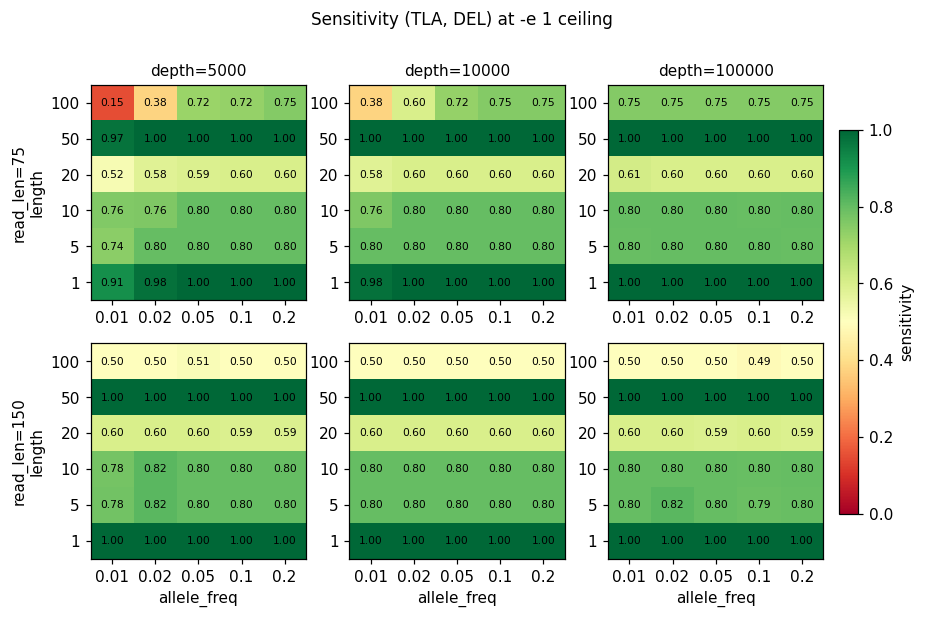

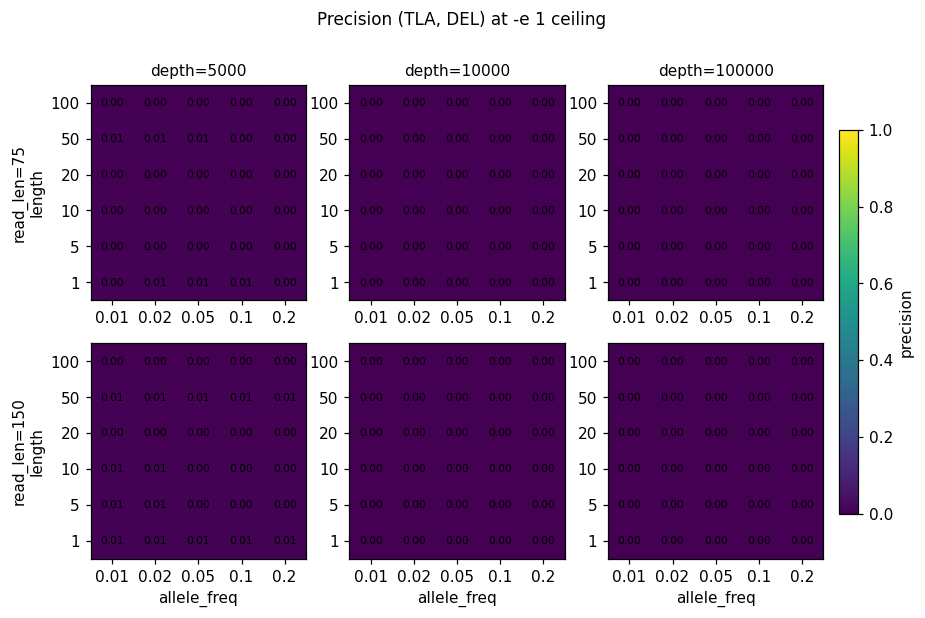

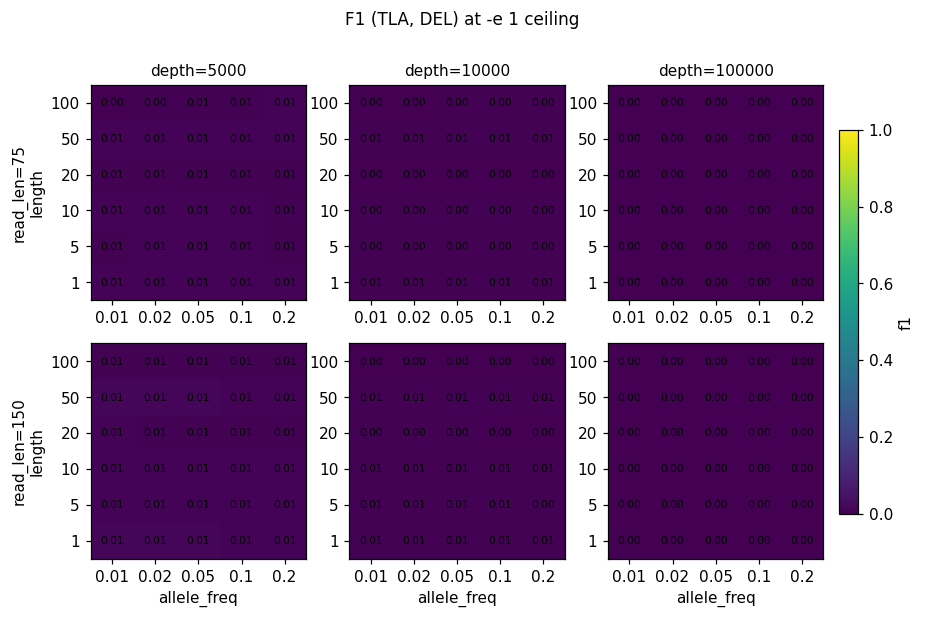

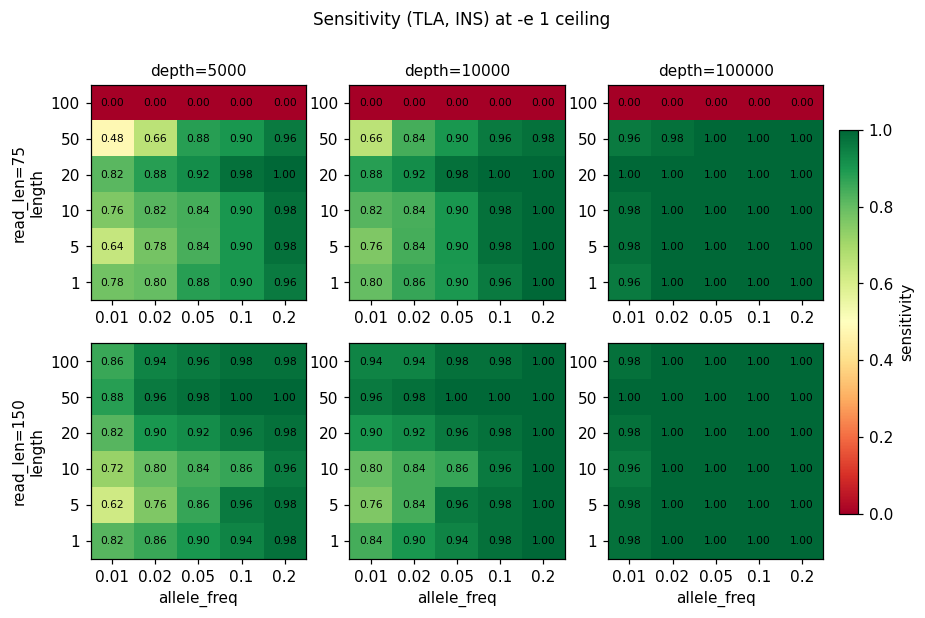

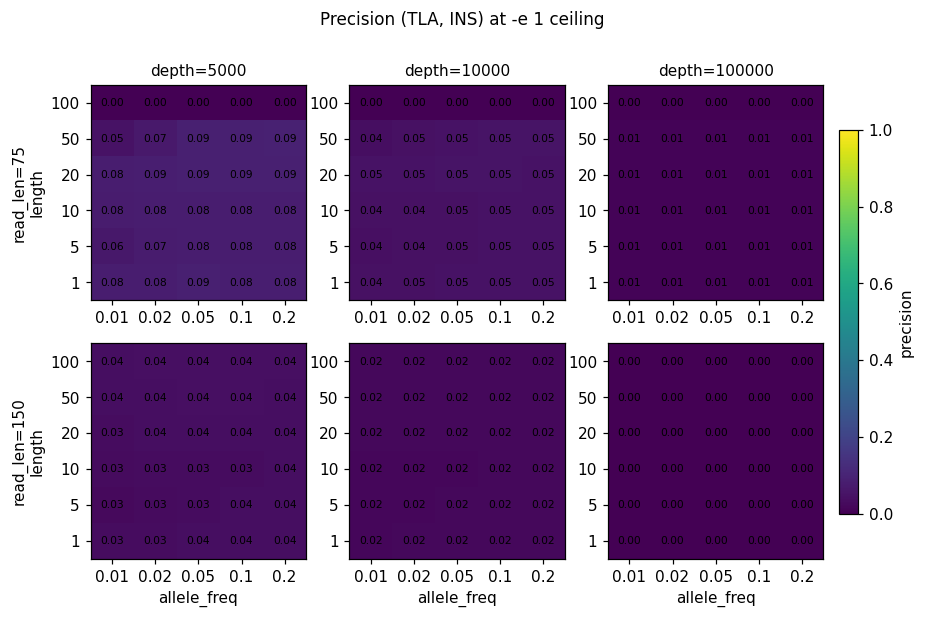

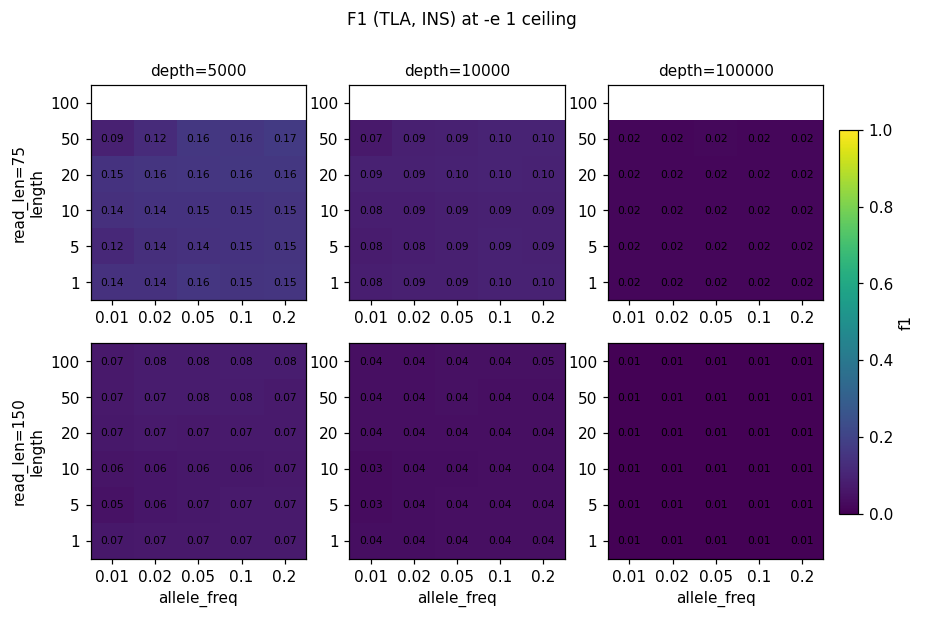

In [20]:
# Experiment A — TLA
if not A_tla["ready"]:
    print("Experiment A / tla not ready — skipping.")
else:
    for itype in ["del", "ins"]:
        d = A_tla["conf"][(A_tla["conf"]["dataset"] == "tla") & (A_tla["conf"]["indel_type"] == itype)]
        for metric, cmap in [("sensitivity", "RdYlGn"),
                             ("precision", "viridis"),
                             ("f1", "viridis")]:
            facet_heatmaps(
                d, value=metric, x="allele_freq", y="length",
                facet_row="read_len", facet_col="depth",
                title=f"{metric.capitalize()} (TLA, {itype.upper()}) at -e 1 ceiling",
                cmap=cmap)


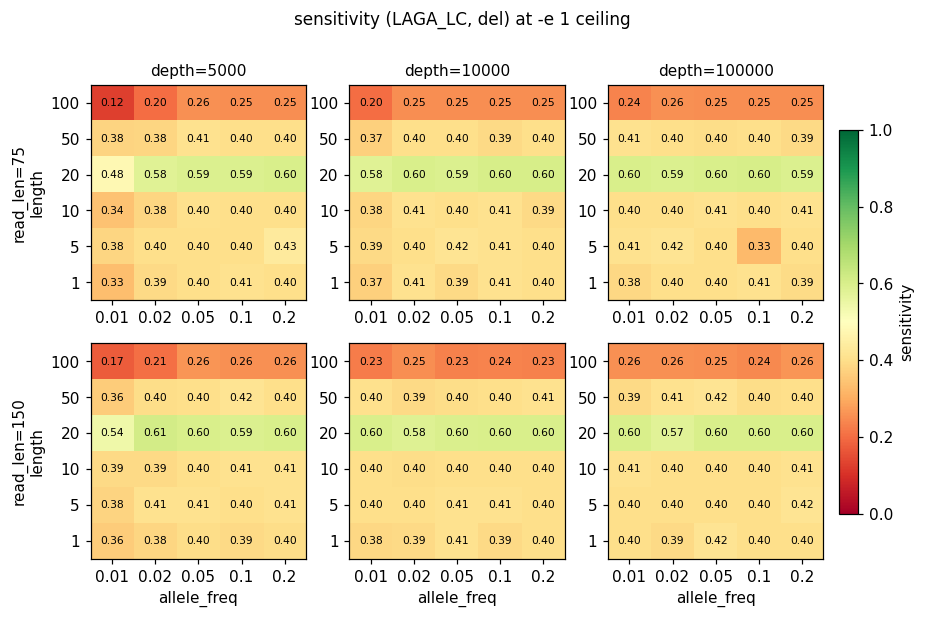

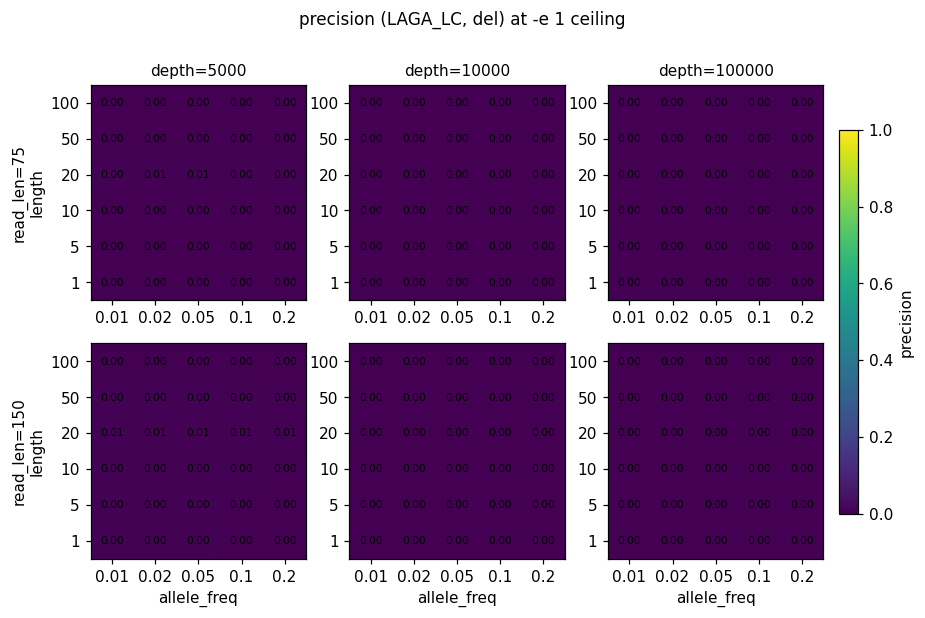

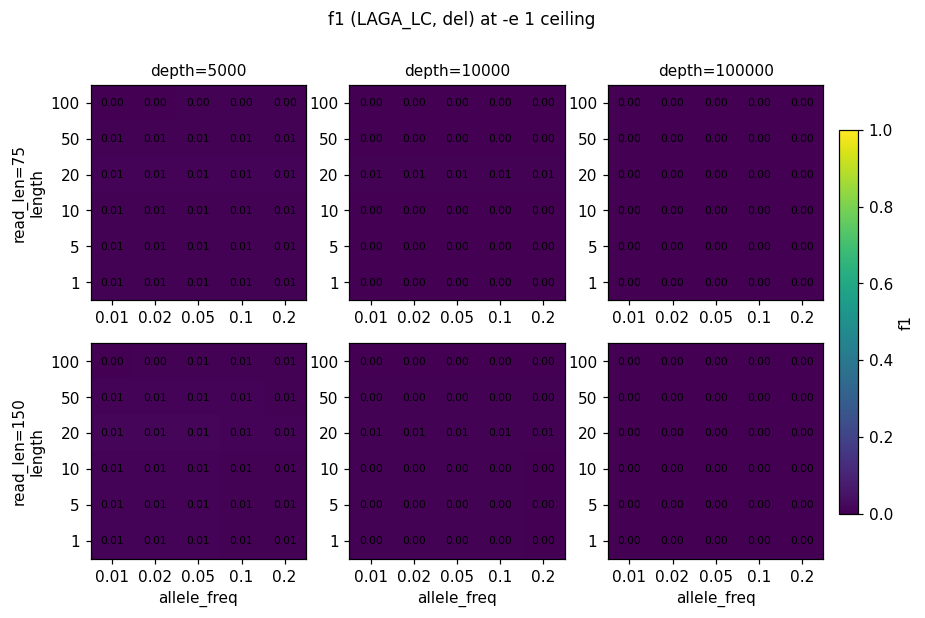

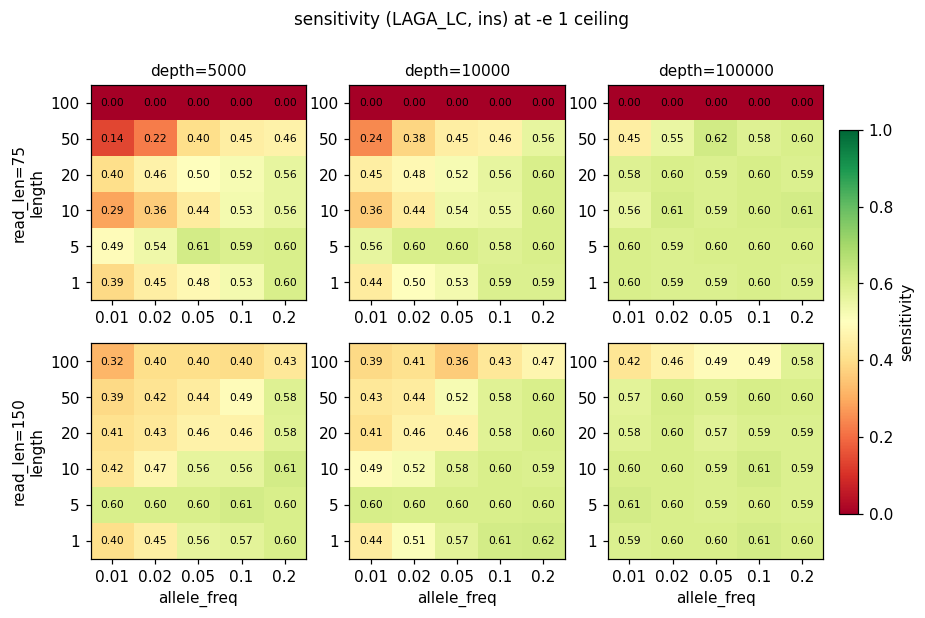

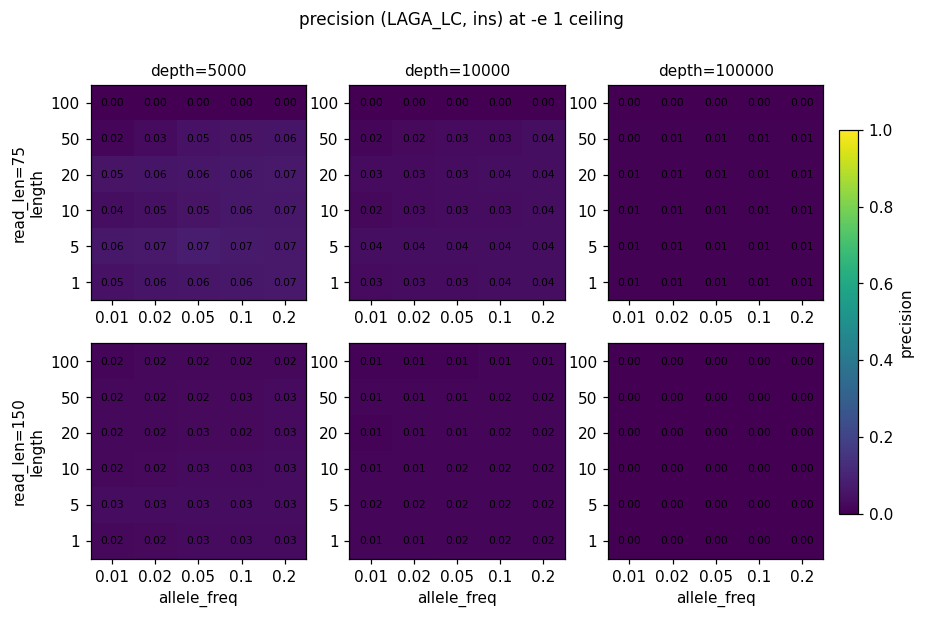

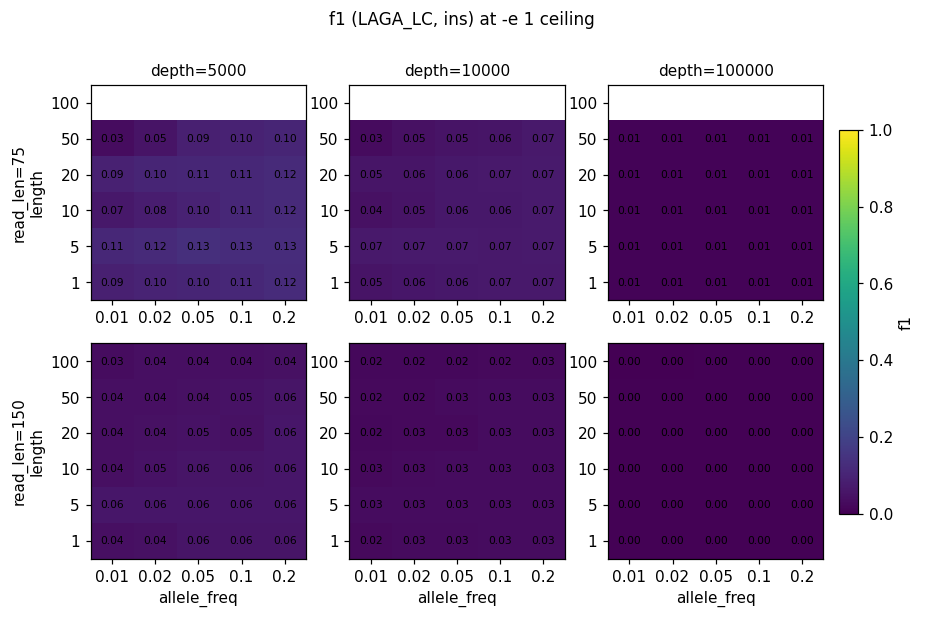

In [21]:
# Experiment A — LAGA_LC
if not A_lc["ready"]:
    print("Experiment A / LAGA_LC not ready — skipping.")
else:
    for itype in ["del", "ins"]:
        d = A_lc["conf"][(A_lc["conf"]["dataset"] == "LAGA_LC") & (A_lc["conf"]["indel_type"] == itype) & (A_lc["conf"]["read_len"] != 250)]
        for metric, cmap in [("sensitivity", "RdYlGn"),
                             ("precision", "viridis"),
                             ("f1", "viridis")]:
            facet_heatmaps(
                d, value=metric, x="allele_freq", y="length",
                facet_row="read_len", facet_col="depth",
                title=f"{metric} (LAGA_LC, {itype}) at -e 1 ceiling",
                cmap=cmap)


### How to read Experiment A

- **Small indels (1–20 bp)** are found down to 1% AF at every read length.
- **Large indels (50, 100 bp) drop out at short reads** — a 100 bp event can't fit in a 75 bp read; longer reads recover it. A length-vs-read-length limit, not an AF limit.
- **Depth barely moves the ceiling** — at `-e 1`, one spanning mutant read is enough. Depth matters for the *threshold* (Exp C), not raw detectability.
- **Precision/F1 are low** across the board at `-e 1` — expected, and the setup for Exp C.
- Compare `tla` vs `LAGA_LC`: matching maps mean the limit is driven by length/AF/read-length, not local sequence.


## Experiment B — positional blind spots

A single moderate event (10 bp, AF 10%, depth 5000) is walked across the amplicon. With 2×75 bp reads the pair covers only the two ends, leaving a center gap Pindel can't span; longer reads shrink then close it.


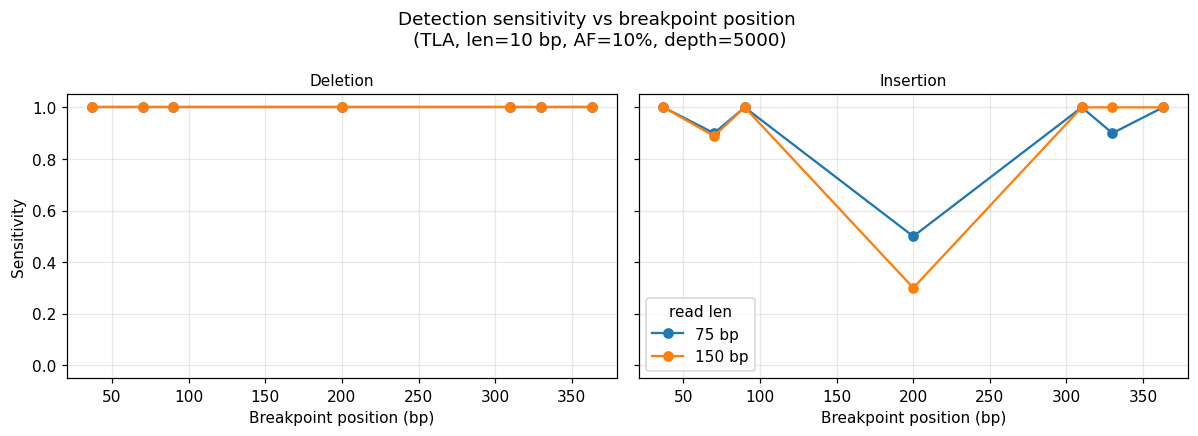

In [22]:
# Experiment B — TLA
if not B_tla["ready"]:
    print("Experiment B / tla not ready — skipping.")
else:
    pos_rate = (B_tla["mut"]
                .groupby(["read_len", "indel_type", "amplicon_pos"])["detected"]
                .mean().reset_index())

    ITYPE_LABELS = {"del": "Deletion", "ins": "Insertion"}
    itypes = sorted(pos_rate["indel_type"].unique())
    fig, axes = plt.subplots(1, len(itypes), figsize=(11, 4),
                             squeeze=False, sharey=True)
    for j, itype in enumerate(itypes):
        ax = axes[0][j]
        sub = pos_rate[pos_rate["indel_type"] == itype]
        for rl, g in sub.groupby("read_len"):
            g = g.sort_values("amplicon_pos")
            ax.plot(g["amplicon_pos"], g["detected"], marker="o", label=f"{rl} bp")
        ax.set_title(ITYPE_LABELS.get(itype, itype))
        ax.set_xlabel("Breakpoint position (bp)")
        ax.set_ylim(-0.05, 1.05)
        ax.grid(alpha=0.3)
    axes[0][0].set_ylabel("Sensitivity")
    axes[0][-1].legend(title="read len")
    fig.suptitle("Detection sensitivity vs breakpoint position \n"
                 "(TLA, len=10 bp, AF=10%, depth=5000)")
    plt.tight_layout()
    plt.show()


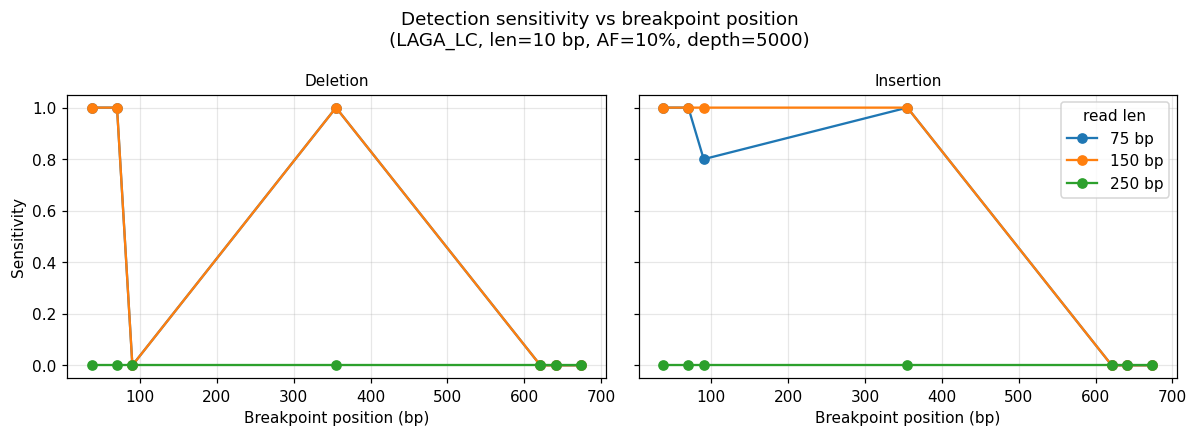

In [23]:
# Experiment B — LAGA_LC
if not B_lc["ready"]:
    print("Experiment B / LAGA_LC not ready — skipping.")
else:
    pos_rate_lc = (B_lc["mut"]
                   .groupby(["read_len", "indel_type", "amplicon_pos"])["detected"]
                   .mean().reset_index())

    ITYPE_LABELS = {"del": "Deletion", "ins": "Insertion"}
    itypes_lc = sorted(pos_rate_lc["indel_type"].unique())
    fig, axes = plt.subplots(1, len(itypes_lc), figsize=(11, 4),
                             squeeze=False, sharey=True)
    for j, itype in enumerate(itypes_lc):
        ax = axes[0][j]
        sub = pos_rate_lc[pos_rate_lc["indel_type"] == itype]
        for rl, g in sub.groupby("read_len"):
            g = g.sort_values("amplicon_pos")
            ax.plot(g["amplicon_pos"], g["detected"], marker="o", label=f"{rl} bp")
        ax.set_title(ITYPE_LABELS.get(itype, itype))
        ax.set_xlabel("Breakpoint position (bp)")
        ax.set_ylim(-0.05, 1.05)
        ax.grid(alpha=0.3)
    axes[0][0].set_ylabel("Sensitivity")
    axes[0][-1].legend(title="read len")
    fig.suptitle("Detection sensitivity vs breakpoint position\n"
                 "(LAGA_LC, len=10 bp, AF=10%, depth=5000)")
    plt.tight_layout()
    plt.show()


### How to read Experiment B

**Simulation note:** ART places fragments uniformly (not primer-anchored), so the center gap is partially filled here (~0.5 at center, not 0). Real amplicons have a true zero-coverage center.

**Insertions are position-dependent but deletions are not:**
- *Deletions* — any spanning read carries a `D` CIGAR op regardless of anchor length; Pindel finds these reliably.
- *Insertions* — a 75 bp read over a 10 bp insertion has short anchor → BWA soft-clips → Pindel detects. A 150 bp read has long anchor → BWA emits CIGAR `I` (no soft-clip) → Pindel misses. A fundamental Pindel limit for long-read insertions.

**Takeaway:** for insertions, shorter reads can help Pindel, and center insertions are more vulnerable than deletions. Add a CIGAR-aware caller (VarScan2, GATK) for insertions.


## Experiment C — support threshold (`-e`)

Post-hoc re-score of Experiment A's base VCFs over a challenging subset (**AF 1–2%, lengths 1–20 bp**), swept independently at each depth (5000 / 10 000 / 100 000) plus WT controls. Two rules: **absolute** `-e` (min alt reads) and **fractional** (alt / (ref+alt) from Pindel AD). Goal: read the sensitivity/precision/F1 curves and pick the operating threshold that maximises F1 at each depth.

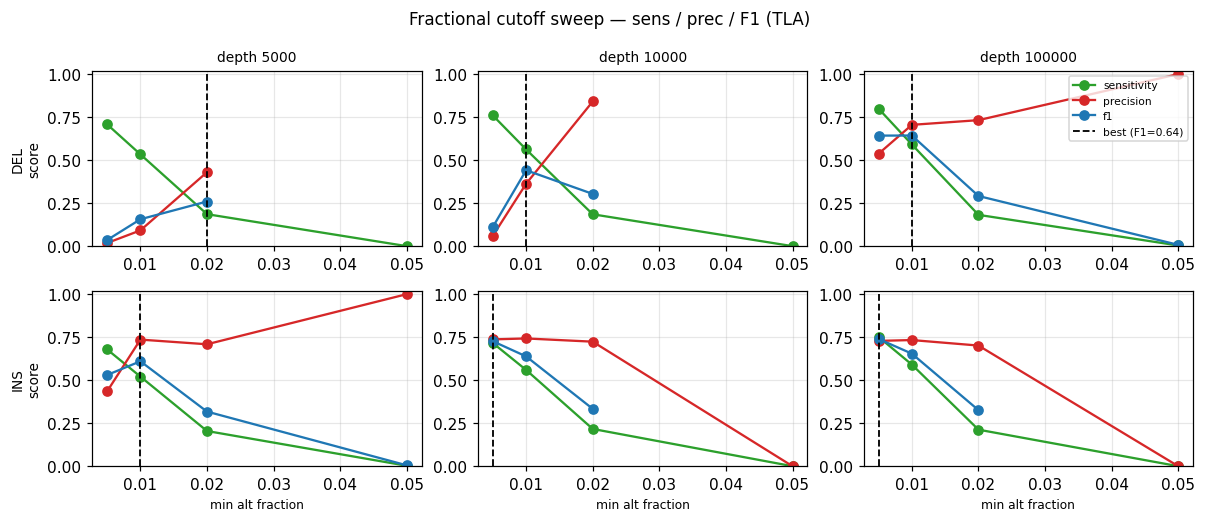

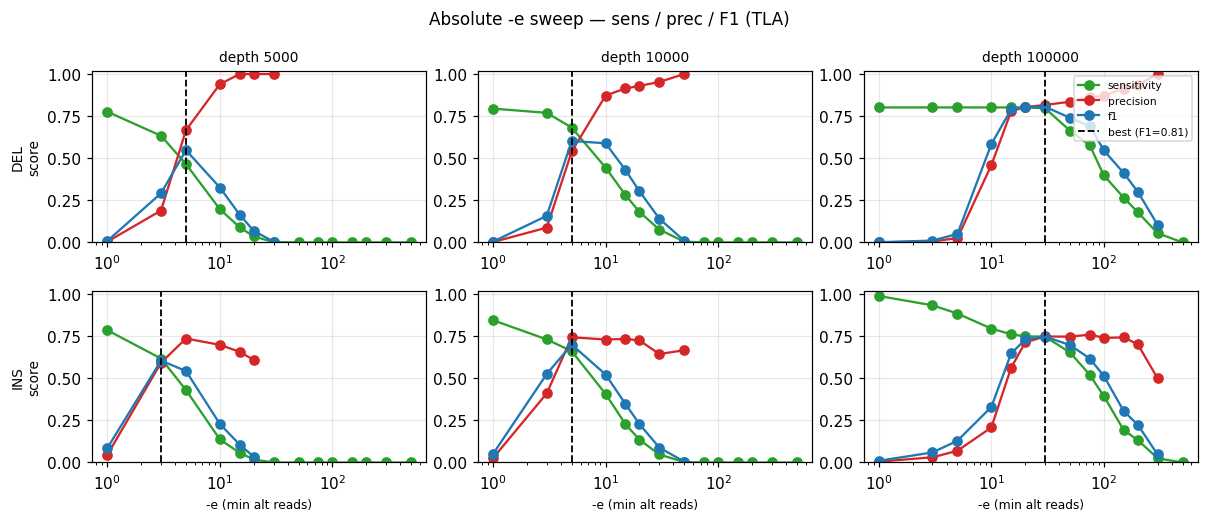

   depth  best -e     F1   sens   prec  best_e/depth
    5000        5  0.546  0.448  0.698       0.00100
   10000        5  0.647  0.671  0.624       0.00050
  100000       30  0.777  0.772  0.782       0.00030

   depth  best frac     F1   sens   prec
    5000       0.02  0.287  0.195  0.542
   10000       0.01  0.521  0.561  0.487
  100000      0.005  0.686  0.775  0.615


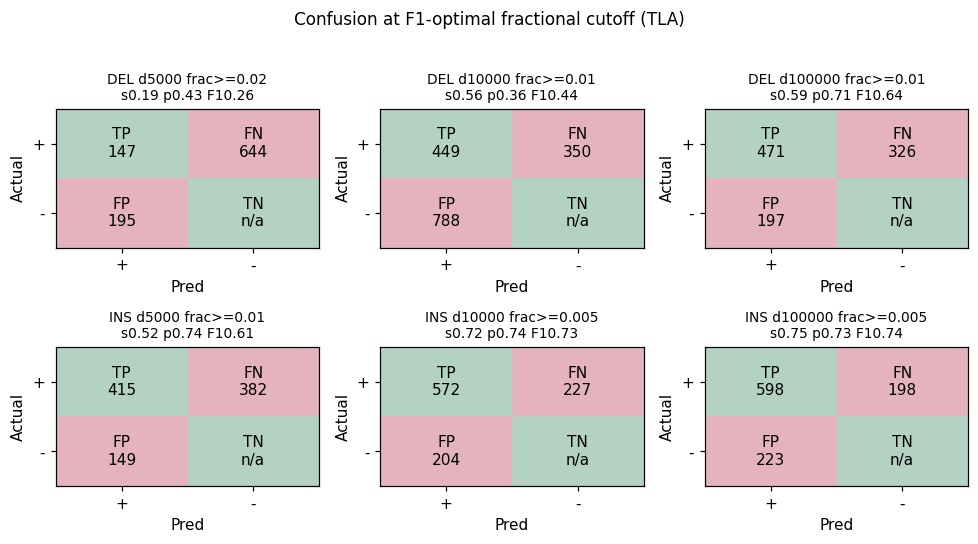

In [24]:
# Experiment C — TLA
if not C_tla["ready"]:
    print("Experiment C / tla not ready — skipping.")
else:
    sweep = C_tla["sweep"]
    depths = sorted(sweep["depth"].unique())
    colors = {"sensitivity": "#2ca02c", "precision": "#d62728", "f1": "#1f77b4"}
    itypes = ["del", "ins"]
    itype_labels = {"del": "DEL", "ins": "INS"}

    # --- Fractional sweep: 2 rows (DEL/INS) × 3 cols (depths) ----------------
    fig, axes = plt.subplots(2, len(depths), figsize=(11, 4.8), squeeze=False)
    for i, itype in enumerate(itypes):
        for j, depth in enumerate(depths):
            ax = axes[i][j]
            s = (sweep[(sweep["depth"] == depth)
                       & (sweep["threshold_type"] == "fraction")
                       & (sweep["indel_type"] == itype)]
                 .sort_values("threshold"))
            for metric, color in colors.items():
                ax.plot(s["threshold"], s[metric], marker="o", color=color,
                        label=metric)
            s_f1 = s.assign(f1=pd.to_numeric(s["f1"], errors="coerce"))
            if not s_f1["f1"].dropna().empty:
                best = s_f1.loc[s_f1["f1"].idxmax()]
                ax.axvline(best["threshold"], color="black", ls="--", lw=1.2,
                           label=f"best (F1={best['f1']:.2f})")
            ax.set_ylim(0, 1.02)
            ax.grid(alpha=0.3)
            if i == 0:
                ax.set_title(f"depth {depth}", fontsize=9)
            if i == 1:
                ax.set_xlabel("min alt fraction", fontsize=8)
            if j == 0:
                ax.set_ylabel(f"{itype_labels[itype]}\nscore", fontsize=9)
            if i == 0 and j == len(depths) - 1:
                ax.legend(fontsize=7, loc="upper right")
    fig.suptitle("Fractional cutoff sweep — sens / prec / F1 (TLA)", fontsize=11)
    plt.tight_layout()
    plt.show()

    # --- Absolute -e sweep: 2 rows (DEL/INS) × 3 cols (depths) ---------------
    fig, axes = plt.subplots(2, len(depths), figsize=(11, 4.8), squeeze=False)
    for i, itype in enumerate(itypes):
        for j, depth in enumerate(depths):
            ax = axes[i][j]
            s = (sweep[(sweep["depth"] == depth)
                       & (sweep["threshold_type"] == "absolute")
                       & (sweep["indel_type"] == itype)]
                 .sort_values("threshold"))
            for metric, color in colors.items():
                ax.plot(s["threshold"], s[metric], marker="o", color=color,
                        label=metric)
            s_f1 = s.assign(f1=pd.to_numeric(s["f1"], errors="coerce"))
            if not s_f1["f1"].dropna().empty:
                best = s_f1.loc[s_f1["f1"].idxmax()]
                ax.axvline(best["threshold"], color="black", ls="--", lw=1.2,
                           label=f"best (F1={best['f1']:.2f})")
            ax.set_xscale("log")
            ax.set_ylim(0, 1.02)
            ax.grid(alpha=0.3)
            if i == 0:
                ax.set_title(f"depth {depth}", fontsize=9)
            if i == 1:
                ax.set_xlabel("-e (min alt reads)", fontsize=8)
            if j == 0:
                ax.set_ylabel(f"{itype_labels[itype]}\nscore", fontsize=9)
            if i == 0 and j == len(depths) - 1:
                ax.legend(fontsize=7, loc="upper right")
    fig.suptitle("Absolute -e sweep — sens / prec / F1 (TLA)", fontsize=11)
    plt.tight_layout()
    plt.show()

    # --- Optimal thresholds table (pooled = 'all') ----------------------------
    sweep_all = sweep[sweep["indel_type"] == "all"]
    print(f"{'depth':>8} {'best -e':>8} {'F1':>6} {'sens':>6} "
          f"{'prec':>6} {'best_e/depth':>13}")
    for depth in depths:
        a = sweep_all[(sweep_all["depth"] == depth)
                      & (sweep_all["threshold_type"] == "absolute")].copy()
        a["f1"] = pd.to_numeric(a["f1"], errors="coerce")
        b = a.loc[a["f1"].idxmax()]
        print(f"{depth:>8} {b['threshold']:>8g} "
              f"{b['f1']:>6.3f} {b['sensitivity']:>6.3f} {b['precision']:>6.3f} "
              f"{b['threshold']/depth:>13.5f}")

    print()
    print(f"{'depth':>8} {'best frac':>10} {'F1':>6} {'sens':>6} {'prec':>6}")
    for depth in depths:
        a = sweep_all[(sweep_all["depth"] == depth)
                      & (sweep_all["threshold_type"] == "fraction")].copy()
        a["f1"] = pd.to_numeric(a["f1"], errors="coerce")
        if a["f1"].dropna().empty:
            continue
        b = a.loc[a["f1"].idxmax()]
        print(f"{depth:>8} {b['threshold']:>10g} "
              f"{b['f1']:>6.3f} {b['sensitivity']:>6.3f} {b['precision']:>6.3f}")

    # --- Confusion matrix: 2 rows (DEL/INS) × 3 cols (depths) ----------------
    frac = sweep[sweep["threshold_type"] == "fraction"].copy()
    frac["f1"] = pd.to_numeric(frac["f1"], errors="coerce")
    fig, axes = plt.subplots(2, len(depths), figsize=(9, 4.8), squeeze=False)
    for i, itype in enumerate(itypes):
        for j, depth in enumerate(depths):
            fd = frac[(frac["depth"] == depth) & (frac["indel_type"] == itype)]
            ax = axes[i][j]
            if fd["f1"].dropna().empty:
                ax.axis("off")
                continue
            b = fd.loc[fd["f1"].idxmax()]
            confusion_panel(ax, b["TP"], b["FP"], b["FN"],
                            title=(f"{itype_labels[itype]} d{depth} "
                                   f"frac>={b['threshold']:g}\n"
                                   f"s{b['sensitivity']:.2f} "
                                   f"p{b['precision']:.2f} "
                                   f"F1{b['f1']:.2f}"))
    fig.suptitle("Confusion at F1-optimal fractional cutoff (TLA)", y=1.02,
                 fontsize=11)
    plt.tight_layout()
    plt.show()


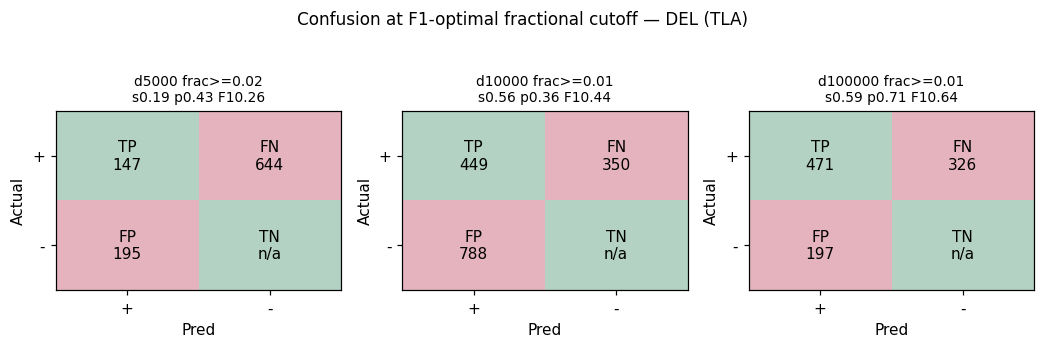

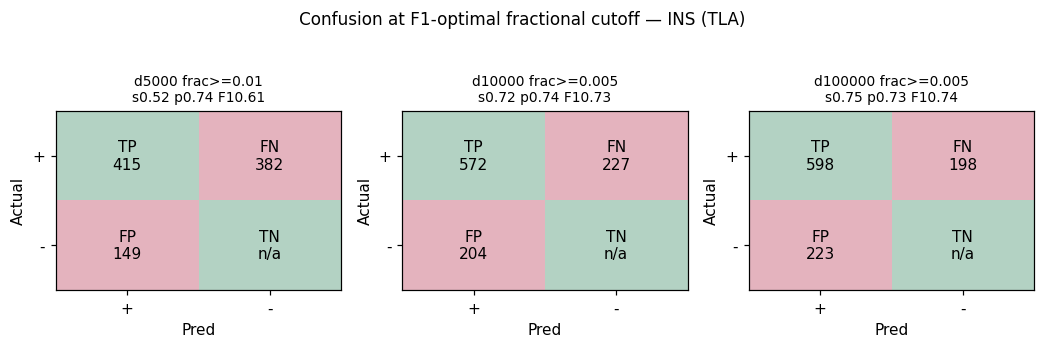

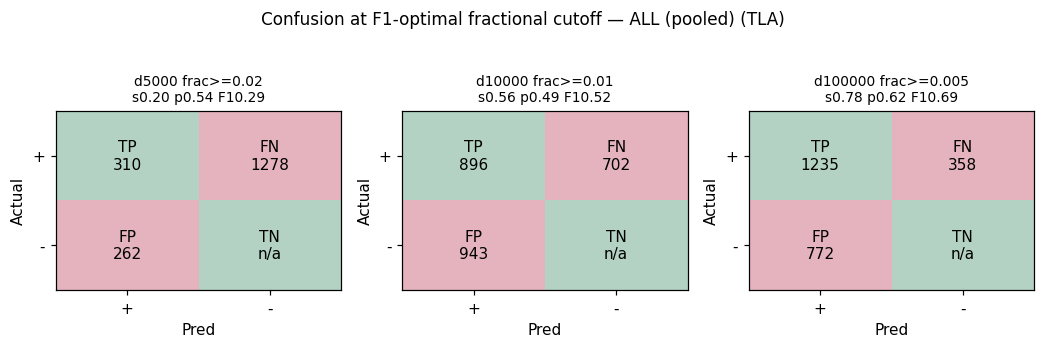

In [25]:
# Experiment C — TLA: confusion matrices per indel type + pooled
if not C_tla["ready"]:
    print("Experiment C / tla not ready — skipping.")
else:
    sweep = C_tla["sweep"]
    depths = sorted(sweep["depth"].unique())
    itype_labels = {"del": "DEL", "ins": "INS", "all": "ALL (pooled)"}

    frac = sweep[sweep["threshold_type"] == "fraction"].copy()
    frac["f1"] = pd.to_numeric(frac["f1"], errors="coerce")

    # One figure per indel type: DEL, INS, and pooled ALL.
    for itype in ["del", "ins", "all"]:
        fig, axes = plt.subplots(1, len(depths),
                                 figsize=(3.2 * len(depths), 3.0),
                                 squeeze=False)
        for j, depth in enumerate(depths):
            fd = frac[(frac["depth"] == depth) & (frac["indel_type"] == itype)]
            ax = axes[0][j]
            if fd["f1"].dropna().empty:
                ax.axis("off")
                continue
            b = fd.loc[fd["f1"].idxmax()]
            confusion_panel(ax, b["TP"], b["FP"], b["FN"],
                            title=(f"d{depth} frac>={b['threshold']:g}\n"
                                   f"s{b['sensitivity']:.2f} "
                                   f"p{b['precision']:.2f} "
                                   f"F1{b['f1']:.2f}"))
        fig.suptitle(
            f"Confusion at F1-optimal fractional cutoff — "
            f"{itype_labels[itype]} (TLA)",
            y=1.04, fontsize=11)
        plt.tight_layout()
        plt.show()

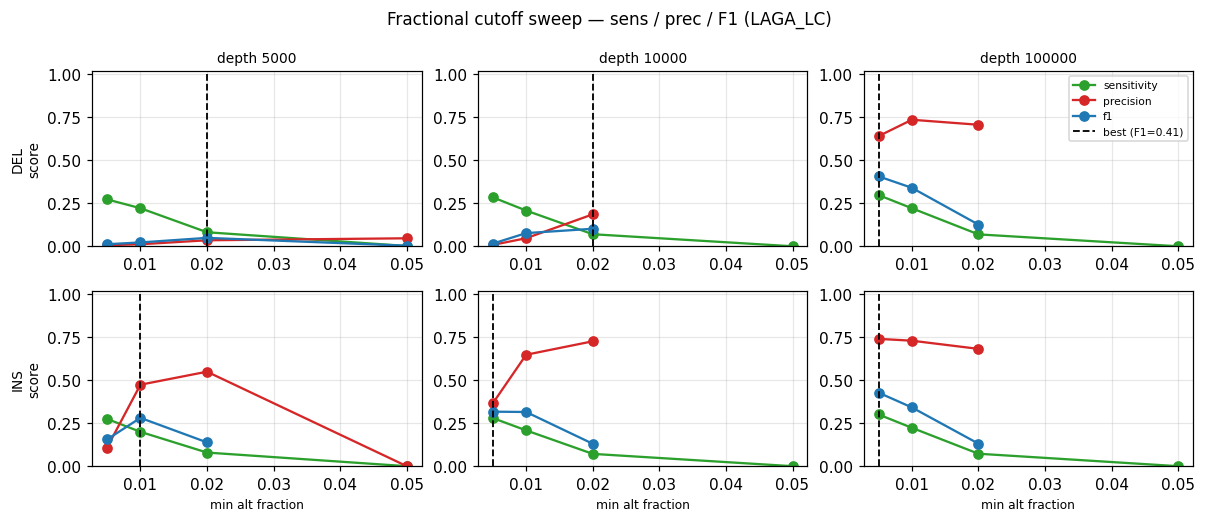

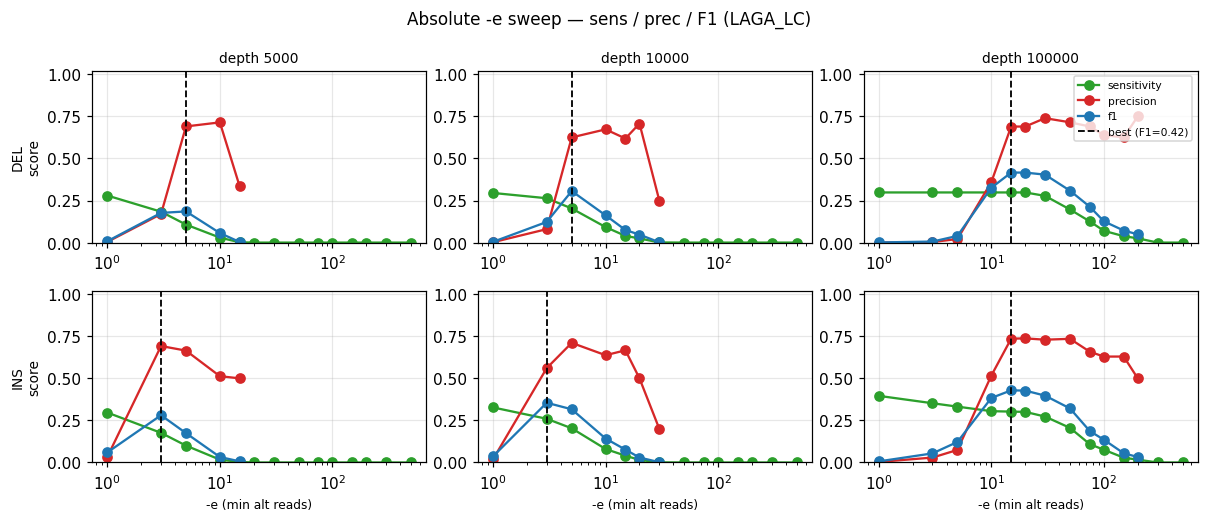

   depth  best -e     F1   sens   prec  best_e/depth
    5000        3  0.216  0.180  0.269       0.00060
   10000        5  0.311  0.203  0.665       0.00050
  100000       15  0.422  0.300  0.712       0.00015

   depth  best frac     F1   sens   prec
    5000       0.02  0.072  0.081  0.065
   10000       0.01  0.123  0.208  0.088
  100000      0.005  0.417  0.299  0.687


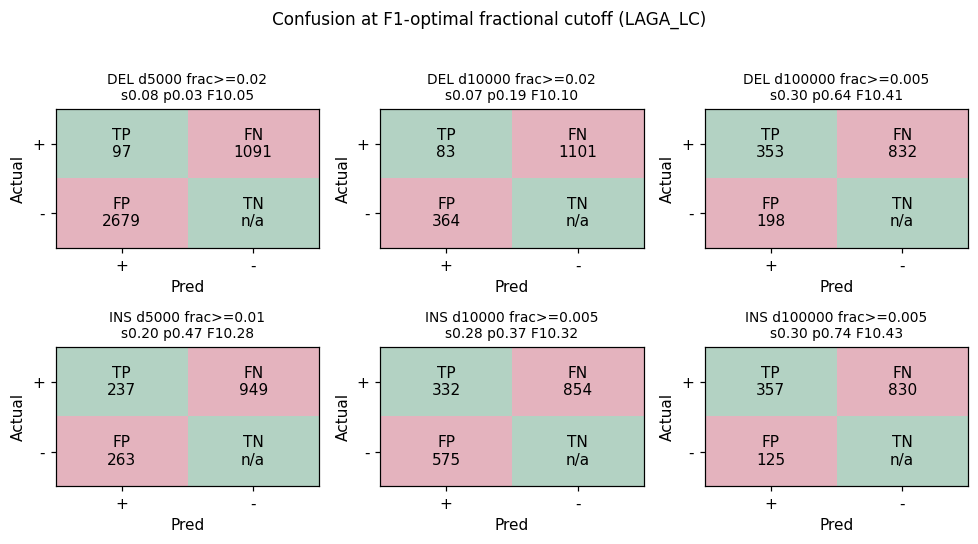

In [26]:
# Experiment C — LAGA_LC
if not C_lc["ready"]:
    print("Experiment C / LAGA_LC not ready — skipping.")
else:
    sweep = C_lc["sweep"]
    depths = sorted(sweep["depth"].unique())
    colors = {"sensitivity": "#2ca02c", "precision": "#d62728", "f1": "#1f77b4"}
    itypes = ["del", "ins"]
    itype_labels = {"del": "DEL", "ins": "INS"}

    # --- Fractional sweep: 2 rows (DEL/INS) × 3 cols (depths) ----------------
    fig, axes = plt.subplots(2, len(depths), figsize=(11, 4.8), squeeze=False)
    for i, itype in enumerate(itypes):
        for j, depth in enumerate(depths):
            ax = axes[i][j]
            s = (sweep[(sweep["depth"] == depth)
                       & (sweep["threshold_type"] == "fraction")
                       & (sweep["indel_type"] == itype)]
                 .sort_values("threshold"))
            for metric, color in colors.items():
                ax.plot(s["threshold"], s[metric], marker="o", color=color,
                        label=metric)
            s_f1 = s.assign(f1=pd.to_numeric(s["f1"], errors="coerce"))
            if not s_f1["f1"].dropna().empty:
                best = s_f1.loc[s_f1["f1"].idxmax()]
                ax.axvline(best["threshold"], color="black", ls="--", lw=1.2,
                           label=f"best (F1={best['f1']:.2f})")
            ax.set_ylim(0, 1.02)
            ax.grid(alpha=0.3)
            if i == 0:
                ax.set_title(f"depth {depth}", fontsize=9)
            if i == 1:
                ax.set_xlabel("min alt fraction", fontsize=8)
            if j == 0:
                ax.set_ylabel(f"{itype_labels[itype]}\nscore", fontsize=9)
            if i == 0 and j == len(depths) - 1:
                ax.legend(fontsize=7, loc="upper right")
    fig.suptitle("Fractional cutoff sweep — sens / prec / F1 (LAGA_LC)", fontsize=11)
    plt.tight_layout()
    plt.show()

    # --- Absolute -e sweep: 2 rows (DEL/INS) × 3 cols (depths) ---------------
    fig, axes = plt.subplots(2, len(depths), figsize=(11, 4.8), squeeze=False)
    for i, itype in enumerate(itypes):
        for j, depth in enumerate(depths):
            ax = axes[i][j]
            s = (sweep[(sweep["depth"] == depth)
                       & (sweep["threshold_type"] == "absolute")
                       & (sweep["indel_type"] == itype)]
                 .sort_values("threshold"))
            for metric, color in colors.items():
                ax.plot(s["threshold"], s[metric], marker="o", color=color,
                        label=metric)
            s_f1 = s.assign(f1=pd.to_numeric(s["f1"], errors="coerce"))
            if not s_f1["f1"].dropna().empty:
                best = s_f1.loc[s_f1["f1"].idxmax()]
                ax.axvline(best["threshold"], color="black", ls="--", lw=1.2,
                           label=f"best (F1={best['f1']:.2f})")
            ax.set_xscale("log")
            ax.set_ylim(0, 1.02)
            ax.grid(alpha=0.3)
            if i == 0:
                ax.set_title(f"depth {depth}", fontsize=9)
            if i == 1:
                ax.set_xlabel("-e (min alt reads)", fontsize=8)
            if j == 0:
                ax.set_ylabel(f"{itype_labels[itype]}\nscore", fontsize=9)
            if i == 0 and j == len(depths) - 1:
                ax.legend(fontsize=7, loc="upper right")
    fig.suptitle("Absolute -e sweep — sens / prec / F1 (LAGA_LC)", fontsize=11)
    plt.tight_layout()
    plt.show()

    # --- Optimal thresholds table (pooled = 'all') ----------------------------
    sweep_all = sweep[sweep["indel_type"] == "all"]
    print(f"{'depth':>8} {'best -e':>8} {'F1':>6} {'sens':>6} "
          f"{'prec':>6} {'best_e/depth':>13}")
    for depth in depths:
        a = sweep_all[(sweep_all["depth"] == depth)
                      & (sweep_all["threshold_type"] == "absolute")].copy()
        a["f1"] = pd.to_numeric(a["f1"], errors="coerce")
        b = a.loc[a["f1"].idxmax()]
        print(f"{depth:>8} {b['threshold']:>8g} "
              f"{b['f1']:>6.3f} {b['sensitivity']:>6.3f} {b['precision']:>6.3f} "
              f"{b['threshold']/depth:>13.5f}")

    print()
    print(f"{'depth':>8} {'best frac':>10} {'F1':>6} {'sens':>6} {'prec':>6}")
    for depth in depths:
        a = sweep_all[(sweep_all["depth"] == depth)
                      & (sweep_all["threshold_type"] == "fraction")].copy()
        a["f1"] = pd.to_numeric(a["f1"], errors="coerce")
        if a["f1"].dropna().empty:
            continue
        b = a.loc[a["f1"].idxmax()]
        print(f"{depth:>8} {b['threshold']:>10g} "
              f"{b['f1']:>6.3f} {b['sensitivity']:>6.3f} {b['precision']:>6.3f}")

    # --- Confusion matrix: 2 rows (DEL/INS) × 3 cols (depths) ----------------
    frac = sweep[sweep["threshold_type"] == "fraction"].copy()
    frac["f1"] = pd.to_numeric(frac["f1"], errors="coerce")
    fig, axes = plt.subplots(2, len(depths), figsize=(9, 4.8), squeeze=False)
    for i, itype in enumerate(itypes):
        for j, depth in enumerate(depths):
            fd = frac[(frac["depth"] == depth) & (frac["indel_type"] == itype)]
            ax = axes[i][j]
            if fd["f1"].dropna().empty:
                ax.axis("off")
                continue
            b = fd.loc[fd["f1"].idxmax()]
            confusion_panel(ax, b["TP"], b["FP"], b["FN"],
                            title=(f"{itype_labels[itype]} d{depth} "
                                   f"frac>={b['threshold']:g}\n"
                                   f"s{b['sensitivity']:.2f} "
                                   f"p{b['precision']:.2f} "
                                   f"F1{b['f1']:.2f}"))
    fig.suptitle("Confusion at F1-optimal fractional cutoff (LAGA_LC)", y=1.02,
                 fontsize=11)
    plt.tight_layout()
    plt.show()


### How to read Experiment C — picking the operating threshold

F1-optimal thresholds per depth on the `tla` subset:

| depth | best absolute `-e` | best F1 | `best_e / depth` | best fractional cutoff |
|-------|--------------------|---------|------------------|------------------------|
| 5 000   | **5**  | 0.55 | 0.0010 | ~0.5–1% |
| 10 000  | **5**  | 0.65 | 0.0005 | ~0.5–1% |
| 100 000 | **30** | 0.78 | 0.0003 | ~0.5–1% |

**Absolute `-e` does not scale with depth.** The best count grows only sub-linearly (20× more depth → ~6× larger `-e`), and `best_e / depth` shrinks from 0.0010 to 0.0003 — so any fixed `-e = k × depth` rule is too aggressive at high depth and would silently drop real low-AF calls.

**The fractional cutoff is the stable operating point.** Its F1-optimum stays in a tight **0.5–1% (on AD)** band at every depth, so it transfers across the ~5000× benchmark and the ~370 000× real assay without re-tuning.

**Caveat — Pindel `AD` overstates true VAF (~4×).** The fractional cutoff divides by Pindel's own `AD` supporting-read count, not the true mpileup depth, so "1% on AD" is **not** 1% true AF. For a real filter, divide alt reads by the samtools/VarScan depth at the breakpoint rather than trusting Pindel `AD`.

**Recommendation:** operate on a **fractional cutoff (~0.5–1% on AD)**, not a fixed absolute `-e`. Re-run this sweep on `LAGA_LC` once its Experiment A finishes to confirm the band holds on a second amplicon.

## Near-misses (Experiment A)

`nearmiss.csv` holds right-type calls within 15 bp of truth that failed exact scoring (position or size off). Usually microhomology-shifted deletions:

- `pos_offset` = ±1–2 and `size_offset = 0` → pure shift; consider `POS_TOLERANCE` 1–2 bp.
- `size_offset ≠ 0` → wrong breakpoints; keep strict scoring.
- Sort by `homlen` to flag microhomology rows.

> **Optional file** — `nearmiss.csv` is ~30–56 MB and is not tracked in git. The cells below skip silently if the file is absent.


In [27]:
# Near-misses — TLA
if not A_tla["ready"]:
    print("Experiment A / tla not ready — skipping.")
elif A_tla["near"] is None or A_tla["near"].empty:
    print("No near-miss rows for Experiment A.")
else:
    print(f"near-miss rows: {len(A_tla['near'])}")
    summary = (A_tla["near"]
               .groupby(["indel_type", "pos_offset", "size_offset"])
               .size().reset_index(name="count")
               .sort_values("count", ascending=False).head(15))
    print(summary.to_string(index=False))


No near-miss rows for Experiment A.


## Experiment D — caller comparison (Pindel vs VarScan2 vs Mutect2 vs LoFreq)

`compare_callers.py` re-uses Experiment A's condition BAMs (no re-simulation) and re-calls each with four callers, scored against the same truth with the same exact matching (`POS_TOLERANCE = SIZE_TOLERANCE = 0`).

- **pindel** — re-uses A's VCFs but re-scored at a **fractional cutoff on Pindel's own AD** (`alt / (alt + ref) ≥ 1%`, `PINDEL_OPT_FRACTION`) — the operating rule the Exp C sweep found transferable across depth — so sensitivity/precision reflect that operating point, not the `-e 1` ceiling. The cutoff is a fraction of Pindel AD (which overstates true VAF ~4×, see Exp C), **not** a fraction of true depth.
- **varscan** — `samtools mpileup | varscan mpileup2indel`.
- **mutect2** — GATK Mutect2 tumor-only.
- **lofreq** — `lofreq call --call-indels`.

Fixed depth (5000 / 10 000): asks "who detects the event", not depth-scaling (that's C), and keeps GATK fast. GATK per-start downsampling is disabled (`--max-reads-per-alignment-start 0`) since amplicon reads share a primer start. Non-pindel VCFs are `bcftools norm`-normalized so breakpoints align with the truth anchor. The per-caller confusion matrix (below the overall table) is at each caller's operating threshold (pindel `ad_frac ≥ 1%`, others their own default); TN is not counted here.

Run: `conda run -n indel_sim --no-capture-output python compare_callers.py -d tla`



In [28]:
def load_expt_d(dataset):
    """Load Exp D caller-comparison results for one dataset (None if not run)."""
    base = RESULTS / "exptD" / dataset
    sens_p, calls_p = base / "caller_sensitivity.csv", base / "caller_calls.csv"
    if not sens_p.exists():
        print(f"[Exp D/{dataset}] NOT READY — run "
              f"`python compare_callers.py -d {dataset}` first")
        return None
    sens, calls = pd.read_csv(sens_p), pd.read_csv(calls_p)
    print(f"[Exp D/{dataset}] READY — callers: {sorted(sens['caller'].unique())}, "
          f"{len(calls)} call rows")
    return {"sens": sens, "calls": calls}


D_tla = load_expt_d("tla")
D_lc  = load_expt_d("LAGA_LC")


[Exp D/tla] READY — callers: ['lofreq', 'mutect2', 'pindel', 'varscan'], 1924 call rows
[Exp D/LAGA_LC] READY — callers: ['lofreq', 'mutect2', 'pindel', 'varscan'], 2884 call rows


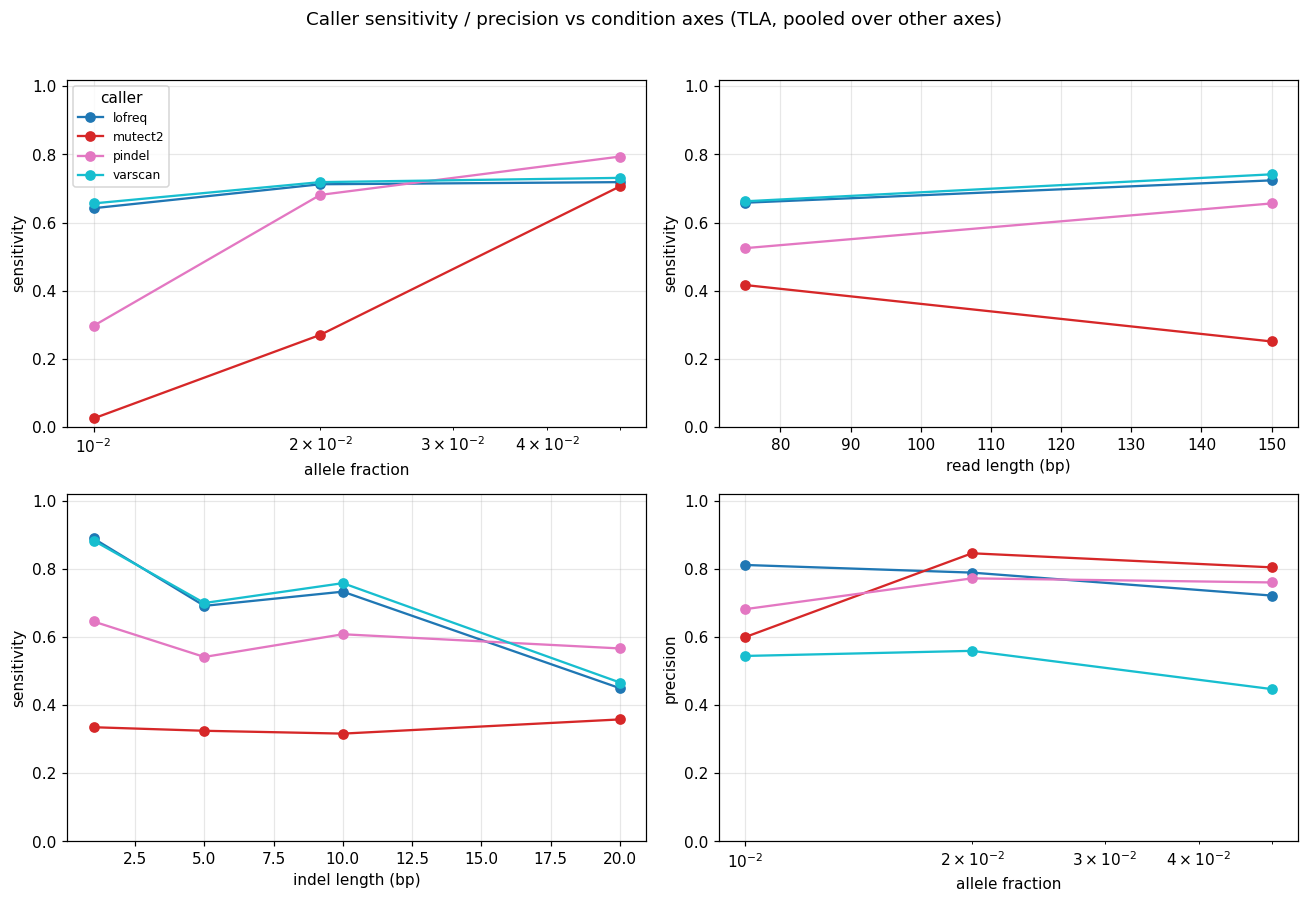

Overall (micro-averaged over the reduced grid):
          TP   FP   FN  sensitivity  precision     f1
caller                                               
lofreq   329   93  148        0.690      0.780  0.732
mutect2  160   41  317        0.335      0.796  0.472
pindel   282   97  195        0.591      0.744  0.659
varscan  334  421  143        0.700      0.442  0.542


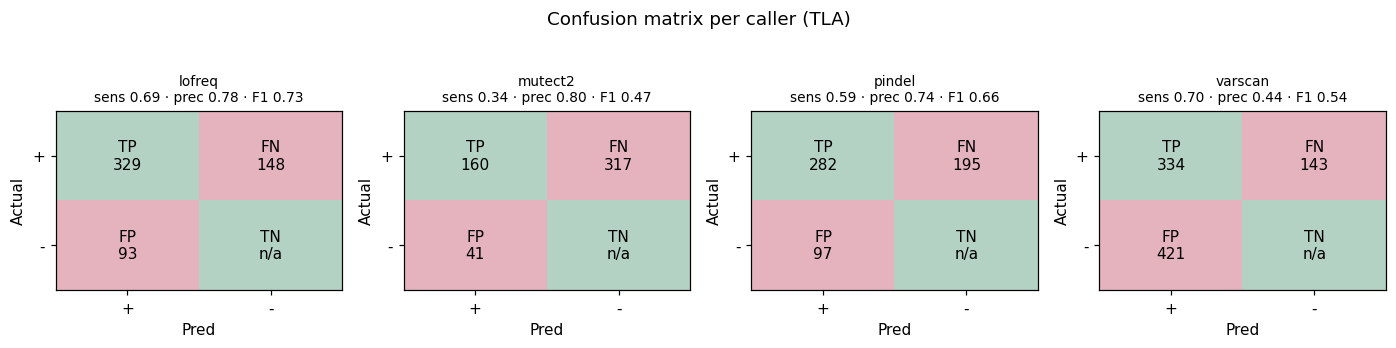

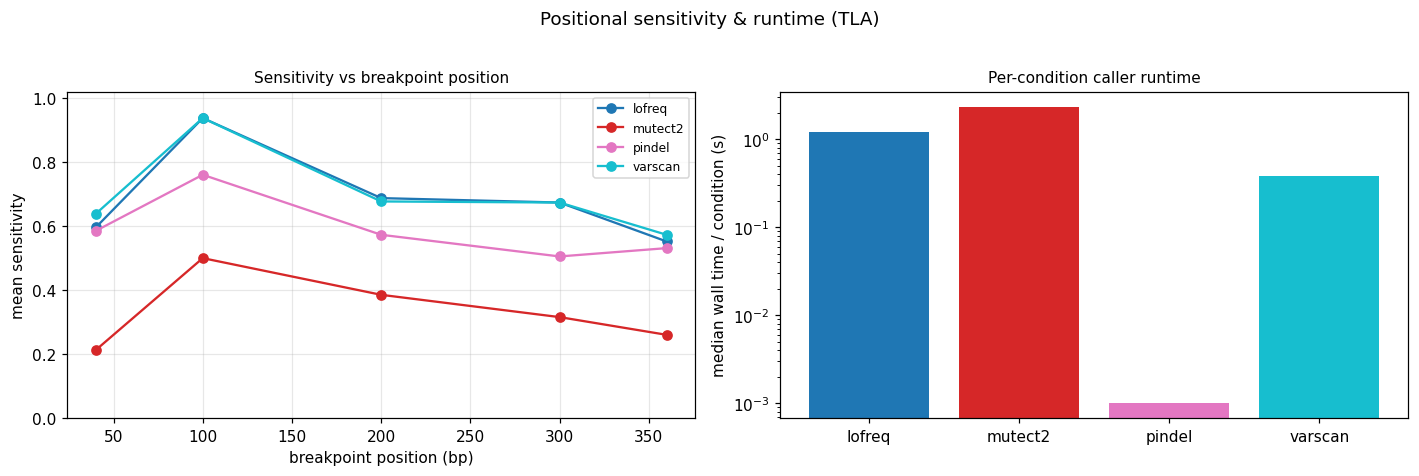

In [29]:
# Experiment D — TLA
name, D_data = "tla", D_tla
if D_data is None:
    print(f"Experiment D / {name} not ready — skipping.")
else:
    sens = D_data["sens"].copy()
    callers = sorted(sens["caller"].unique())
    cpal = dict(zip(callers, plt.cm.tab10(np.linspace(0, 1, max(len(callers), 3)))))
    for c in ["sensitivity", "precision", "f1"]:
        sens[c] = pd.to_numeric(sens[c], errors="coerce")

    # 2×2 panels: sensitivity vs AF / read_len / indel length, + precision vs AF.
    panels = [("allele_freq", "allele fraction", "sensitivity", True),
              ("read_len", "read length (bp)", "sensitivity", False),
              ("length", "indel length (bp)", "sensitivity", False),
              ("allele_freq", "allele fraction", "precision", True)]
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for ax, (xcol, xlabel, metric, logx) in zip(axes.flatten(), panels):
        gg = sens.groupby(["caller", xcol])[metric].mean().reset_index()
        for caller in callers:
            s = gg[gg["caller"] == caller].sort_values(xcol)
            ax.plot(s[xcol], s[metric], marker="o", color=cpal[caller], label=caller)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(metric)
        ax.set_ylim(0, 1.02)
        ax.grid(alpha=0.3)
        if logx:
            ax.set_xscale("log")
    axes.flatten()[0].legend(fontsize=8, title="caller")
    fig.suptitle(f"Caller sensitivity / precision vs condition axes "
                 f"({name.upper()}, pooled over other axes)", y=1.02)
    plt.tight_layout()
    plt.show()

    # Micro-averaged overall metrics per caller (pool TP/FP/FN across all groups).
    agg = sens.groupby("caller")[["TP", "FP", "FN"]].sum()
    agg["sensitivity"] = (agg.TP / (agg.TP + agg.FN)).round(3)
    agg["precision"] = (agg.TP / (agg.TP + agg.FP)).round(3)
    agg["f1"] = (2 * agg.precision * agg.sensitivity
                 / (agg.precision + agg.sensitivity)).round(3)
    print("Overall (micro-averaged over the reduced grid):")
    print(agg.to_string())

    # Confusion matrix per caller at the operating threshold
    # (pindel at Exp C fractional cutoff ad_frac >= 1%; other callers at their own default).
    fig, axes = plt.subplots(1, len(agg), figsize=(3.2 * len(agg), 3.0),
                             squeeze=False)
    for k, caller in enumerate(agg.index):
        r = agg.loc[caller]
        confusion_panel(axes[0][k], r["TP"], r["FP"], r["FN"],
                        title=(f"{caller}\nsens {r['sensitivity']:.2f} · "
                               f"prec {r['precision']:.2f} · F1 {r['f1']:.2f}"))
    fig.suptitle(f"Confusion matrix per caller ({name.upper()})", y=1.04)
    plt.tight_layout()
    plt.show()

    # Positional sensitivity + per-condition runtime.
    calls = D_data["calls"].copy()
    mut = calls[calls["is_control"] == 0].copy()
    mut["detected"] = pd.to_numeric(mut["detected"], errors="coerce")
    callers = sorted(mut["caller"].unique())
    cpal = dict(zip(callers, plt.cm.tab10(np.linspace(0, 1, max(len(callers), 3)))))

    fig, (axp, axr) = plt.subplots(1, 2, figsize=(13, 4.2))

    # Sensitivity vs breakpoint position (exposes positional blind spots).
    pos = mut.groupby(["caller", "amplicon_pos"])["detected"].mean().reset_index()
    for caller in callers:
        s = pos[pos["caller"] == caller].sort_values("amplicon_pos")
        axp.plot(s["amplicon_pos"], s["detected"], marker="o",
                 color=cpal[caller], label=caller)
    axp.set_xlabel("breakpoint position (bp)")
    axp.set_ylabel("mean sensitivity")
    axp.set_ylim(0, 1.02)
    axp.grid(alpha=0.3)
    axp.legend(fontsize=8)
    axp.set_title("Sensitivity vs breakpoint position")

    # Per-condition wall-clock runtime per caller (median; log scale).
    rt = calls.copy()
    rt["runtime_s"] = pd.to_numeric(rt["runtime_s"], errors="coerce")
    med = rt.groupby("caller")["runtime_s"].median().reindex(callers)
    axr.bar(range(len(callers)), med.values, color=[cpal[c] for c in callers])
    axr.set_xticks(range(len(callers)), callers)
    axr.set_ylabel("median wall time / condition (s)")
    axr.set_yscale("log")
    axr.set_title("Per-condition caller runtime")

    fig.suptitle(f"Positional sensitivity & runtime ({name.upper()})", y=1.02)
    plt.tight_layout()
    plt.show()


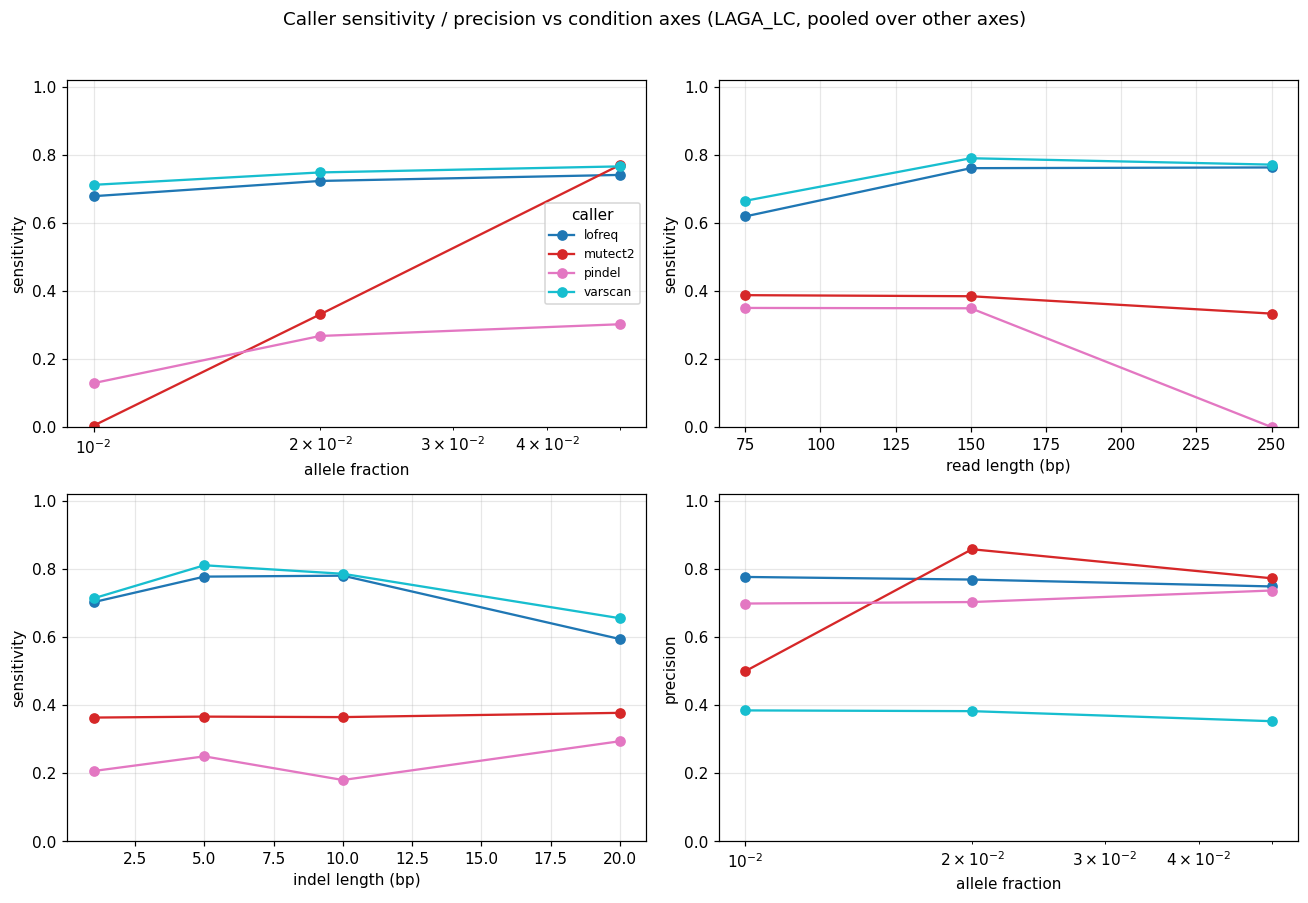

Overall (micro-averaged over the reduced grid):
          TP    FP   FN  sensitivity  precision     f1
caller                                                
lofreq   510   149  205        0.713      0.774  0.742
mutect2  263    70  452        0.368      0.790  0.502
pindel   166    65  549        0.232      0.719  0.351
varscan  530  1440  185        0.741      0.269  0.395


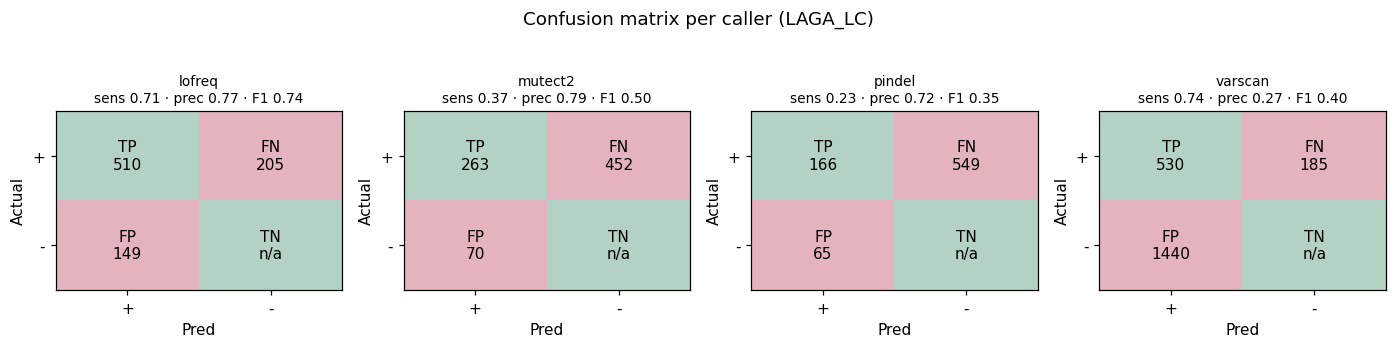

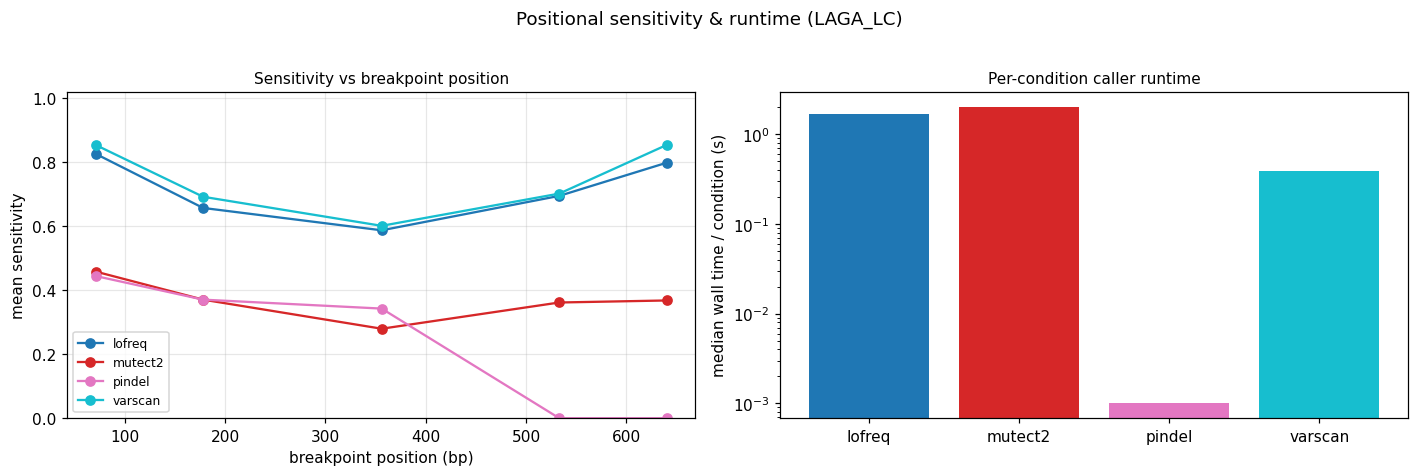

In [30]:
# Experiment D — LAGA_LC
name, D_data = "LAGA_LC", D_lc
if D_data is None:
    print(f"Experiment D / {name} not ready — skipping.")
else:
    sens = D_data["sens"].copy()
    callers = sorted(sens["caller"].unique())
    cpal = dict(zip(callers, plt.cm.tab10(np.linspace(0, 1, max(len(callers), 3)))))
    for c in ["sensitivity", "precision", "f1"]:
        sens[c] = pd.to_numeric(sens[c], errors="coerce")

    # 2×2 panels: sensitivity vs AF / read_len / indel length, + precision vs AF.
    panels = [("allele_freq", "allele fraction", "sensitivity", True),
              ("read_len", "read length (bp)", "sensitivity", False),
              ("length", "indel length (bp)", "sensitivity", False),
              ("allele_freq", "allele fraction", "precision", True)]
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for ax, (xcol, xlabel, metric, logx) in zip(axes.flatten(), panels):
        gg = sens.groupby(["caller", xcol])[metric].mean().reset_index()
        for caller in callers:
            s = gg[gg["caller"] == caller].sort_values(xcol)
            ax.plot(s[xcol], s[metric], marker="o", color=cpal[caller], label=caller)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(metric)
        ax.set_ylim(0, 1.02)
        ax.grid(alpha=0.3)
        if logx:
            ax.set_xscale("log")
    axes.flatten()[0].legend(fontsize=8, title="caller")
    fig.suptitle(f"Caller sensitivity / precision vs condition axes "
                 f"({name.upper()}, pooled over other axes)", y=1.02)
    plt.tight_layout()
    plt.show()

    # Micro-averaged overall metrics per caller (pool TP/FP/FN across all groups).
    agg = sens.groupby("caller")[["TP", "FP", "FN"]].sum()
    agg["sensitivity"] = (agg.TP / (agg.TP + agg.FN)).round(3)
    agg["precision"] = (agg.TP / (agg.TP + agg.FP)).round(3)
    agg["f1"] = (2 * agg.precision * agg.sensitivity
                 / (agg.precision + agg.sensitivity)).round(3)
    print("Overall (micro-averaged over the reduced grid):")
    print(agg.to_string())

    # Confusion matrix per caller at the operating threshold
    # (pindel at Exp C fractional cutoff ad_frac >= 1%; other callers at their own default).
    fig, axes = plt.subplots(1, len(agg), figsize=(3.2 * len(agg), 3.0),
                             squeeze=False)
    for k, caller in enumerate(agg.index):
        r = agg.loc[caller]
        confusion_panel(axes[0][k], r["TP"], r["FP"], r["FN"],
                        title=(f"{caller}\nsens {r['sensitivity']:.2f} · "
                               f"prec {r['precision']:.2f} · F1 {r['f1']:.2f}"))
    fig.suptitle(f"Confusion matrix per caller ({name.upper()})", y=1.04)
    plt.tight_layout()
    plt.show()

    # Positional sensitivity + per-condition runtime.
    calls = D_data["calls"].copy()
    mut = calls[calls["is_control"] == 0].copy()
    mut["detected"] = pd.to_numeric(mut["detected"], errors="coerce")
    callers = sorted(mut["caller"].unique())
    cpal = dict(zip(callers, plt.cm.tab10(np.linspace(0, 1, max(len(callers), 3)))))

    fig, (axp, axr) = plt.subplots(1, 2, figsize=(13, 4.2))

    # Sensitivity vs breakpoint position (exposes positional blind spots).
    pos = mut.groupby(["caller", "amplicon_pos"])["detected"].mean().reset_index()
    for caller in callers:
        s = pos[pos["caller"] == caller].sort_values("amplicon_pos")
        axp.plot(s["amplicon_pos"], s["detected"], marker="o",
                 color=cpal[caller], label=caller)
    axp.set_xlabel("breakpoint position (bp)")
    axp.set_ylabel("mean sensitivity")
    axp.set_ylim(0, 1.02)
    axp.grid(alpha=0.3)
    axp.legend(fontsize=8)
    axp.set_title("Sensitivity vs breakpoint position")

    # Per-condition wall-clock runtime per caller (median; log scale).
    rt = calls.copy()
    rt["runtime_s"] = pd.to_numeric(rt["runtime_s"], errors="coerce")
    med = rt.groupby("caller")["runtime_s"].median().reindex(callers)
    axr.bar(range(len(callers)), med.values, color=[cpal[c] for c in callers])
    axr.set_xticks(range(len(callers)), callers)
    axr.set_ylabel("median wall time / condition (s)")
    axr.set_yscale("log")
    axr.set_title("Per-condition caller runtime")

    fig.suptitle(f"Positional sensitivity & runtime ({name.upper()})", y=1.02)
    plt.tight_layout()
    plt.show()


### How to read these plots

**2×2 panels — caller sensitivity / precision, each pooled over the axes not shown:**
- *Top-left: sensitivity vs allele fraction (log scale)* — the primary question: at what AF does each caller drop out? A flat line to 1% means reliable low-VAF detection; a steep drop shows the detection floor.
- *Top-right: sensitivity vs read length* — whether detection is read-length dependent. Pindel relies on soft-clips, so long reads that BWA encodes as CIGAR `I` instead of soft-clips cause a drop at ≥150 bp for insertions.
- *Bottom-left: sensitivity vs indel length* — the length floor per caller. Very short events (1–5 bp) are hardest; assembly-based callers may drop out while pileup-based ones (VarScan2, LoFreq) stay flat.
- *Bottom-right: precision vs allele fraction* — false-positive rate at each AF level. Low precision at 1–2% AF means the caller emits many off-target calls alongside real ones.

**Overall table + per-caller confusion matrix** — TP/FP/FN summed across all grid groups, then rated. High sensitivity + low precision = caller finds the event but also emits noise. `pindel` is scored at the Exp C operating point — a **fractional cutoff `ad_frac ≥ 1%`** (fraction of Pindel AD, ~4× true VAF), not the `-e 1` ceiling — which trades some sensitivity for much higher precision than Experiment A. The confusion matrix shows the same TP/FP/FN as counts (TN not tracked).

**Positional sensitivity** — cross-caller version of Experiment B. A dip shared by all callers points to an alignment artifact; a dip unique to one caller is a limit of that caller's assembly or pileup logic.



## Finding — Pindel's insert size (`-i`) is un-derivable for amplicons

Zero LAGA sensitivity traced to one parameter: Pindel's config insert size (`-i`), which the benchmark had set to the ART `fragment_mean`. That value suppresses all detection on the LAGA amplicon.

Sweeping only `-i` (BAM fixed):

| dataset | amplicon | fragment | `-i` that recovers truth | `-i = fragment_mean` |
|---|---|---|---|---|
| tla | 400 bp | ~250 | ~250–398 | works (250, lucky) |
| LAGA_LC | 711 bp | ~345 | **~165** | **0 true calls** (350) |

1. **`fragment_mean`, amplicon length, and the hard-coded 398 all fail for LAGA.** The only working value (~165) was found empirically and doesn't transfer to tla.
2. **Total call count misleads** — the true 10 bp deletion is recovered only in a narrow `-i` band; optimizing on raw counts tunes to false positives.
3. **A 3′-end blind spot no `-i` fixes** — near the amplicon end the aligner soft-clips instead of emitting a gap (~8/10 000 reads carry a clean `10D` CIGAR vs ~280 mid-amplicon). A genuine positional result.
4. **Read-length interaction** — Pindel needs `-i ≥ read_len`, so LAGA's `-i` 165 makes r250 conditions unevaluable.

**Why:** `-i` models a fragment-size distribution from random shearing; amplicons have fixed primer geometry with no such distribution.

**Change:** `config.DATASETS[...]["pindel_insert"]` is decoupled from `fragment_mean` (`tla` = 250, `LAGA_LC` = 165). ART still uses `fragment_mean`.

**Implication:** because `-i` can't be derived generally for amplicons, Pindel is a poor production indel caller here — the motivation for Experiment D.


---

## Appendix — Post-hoc: VarScan2 vs Pindel (insertions, Experiment B)

> **Context:** This analysis motivated the multi-caller comparison in Experiment D. It showed Pindel misses insertions that BWA encodes as CIGAR `I` (long reads ≥150 bp), while VarScan2 catches them via mpileup `+NNN` entries. Experiment D now covers this comparison systematically across the full grid. Kept here for reference.

**AF caveat:** both callers misreport AF. VarScan2 `FREQ` = alt / mpileup depth (under-reports at edges); Pindel AD/(AD+RD) over-reports ~4× (Exp C). Report AF as `alt_reads / samtools_depth` for both.

Loaded 138 cached VarScan2 rows.


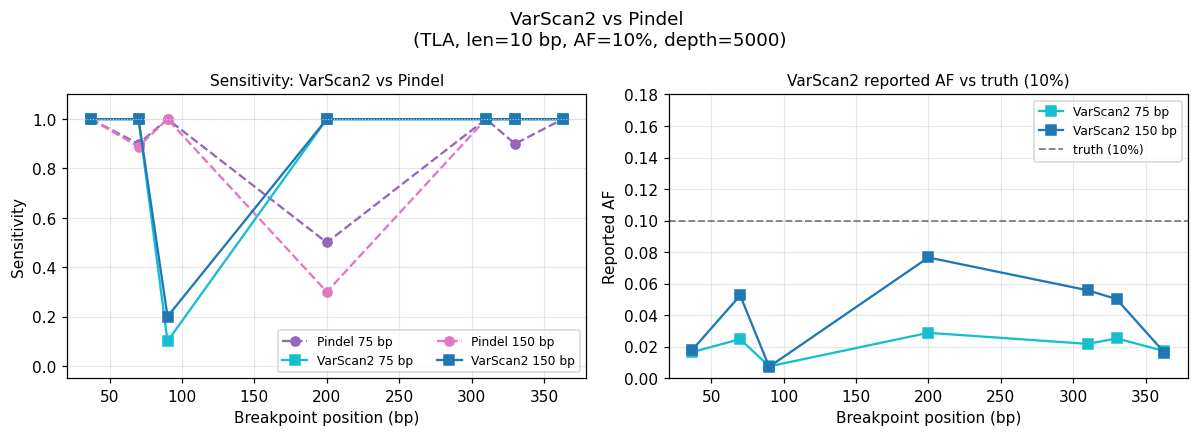

  read_len    VarScan2 mean AF   bias vs truth 10%
        75              0.0222                -78%
       150              0.0435                -56%


In [31]:
# Appendix: VarScan2 vs Pindel (insertions) — TLA
import subprocess
from pathlib import Path

if not B_tla["ready"]:
    print("Exp B / tla not ready — skipping.")
else:
    _POS = "amplicon_pos" if "amplicon_pos" in B_tla["mut"].columns else "indel_pos"

    # ── locate varscan binary ─────────────────────────────────────────────────
    _vs_bin = subprocess.run(
        ["conda", "run", "-n", "indel_sim", "which", "varscan"],
        capture_output=True, text=True).stdout.strip()

    def _varscan_call(mpileup_path):
        """Run VarScan2 mpileup2indel; return (detected, reported_af) for first call."""
        r = subprocess.run(
            [_vs_bin, "mpileup2indel", str(mpileup_path),
             "--min-coverage", "5", "--min-reads2", "1",
             "--min-var-freq", "0.005", "--p-value", "0.99", "--output-vcf", "1"],
            capture_output=True, text=True)
        for line in r.stdout.splitlines():
            if line.startswith("#") or "\t" not in line:
                continue
            parts = line.split("\t")
            if len(parts) < 10:
                continue
            fmt = dict(zip(parts[8].split(":"), parts[9].split(":")))
            freq = fmt.get("FREQ", "")
            if freq:
                return True, float(freq.rstrip("%")) / 100
        return False, float("nan")

    # ── load cache or run batch ───────────────────────────────────────────────
    _cache = BENCH / "exptB" / "tla" / "results" / "_varscan_ins_cache.csv"
    if _cache.exists():
        vs_df = pd.read_csv(_cache)
        print(f"Loaded {len(vs_df)} cached VarScan2 rows.")
    else:
        _cond_root = BENCH / "exptB" / "tla" / "conditions"
        _ins = B_tla["mut"][B_tla["mut"]["indel_type"] == "ins"].copy()
        print(f"Running VarScan2 on {len(_ins)} insertion conditions (cached after first run)...")
        _rows = []
        for i, (_, row) in enumerate(_ins.iterrows()):
            cid = row["cond_id"]
            mp = _cond_root / cid / f"{cid}.mpileup"
            if not mp.exists():
                continue
            vs_det, vs_af = _varscan_call(mp)
            _rows.append({
                _POS: row[_POS], "read_len": int(row["read_len"]),
                "seed": int(row["seed"]),
                "pindel_detected": float(row["detected"]),
                "varscan_detected": float(vs_det),
                "varscan_af": vs_af,
            })
            if (i + 1) % 20 == 0:
                print(f"  {i+1}/{len(_ins)} done")
        vs_df = pd.DataFrame(_rows)
        vs_df.to_csv(_cache, index=False)
        print(f"Done — cached to {_cache.name}")

    # ── plots ─────────────────────────────────────────────────────────────────
    _RL_COLORS = {75: ("#9467bd", "#17becf"), 150: ("#e377c2", "#1f77b4")}
    _det = vs_df.groupby([_POS, "read_len"])[["pindel_detected", "varscan_detected"]].mean().reset_index()
    _af  = vs_df.groupby([_POS, "read_len"])["varscan_af"].mean().reset_index()

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

    for rl, g in _det.groupby("read_len"):
        g = g.sort_values(_POS)
        pcol, vcol = _RL_COLORS.get(int(rl), ("gray", "gray"))
        ax1.plot(g[_POS], g["pindel_detected"], "--o", color=pcol, label=f"Pindel {rl} bp")
        ax1.plot(g[_POS], g["varscan_detected"], "-s",  color=vcol, label=f"VarScan2 {rl} bp")
    ax1.axhline(1, color="lightgray", lw=0.7, ls=":")
    ax1.set_ylim(-0.05, 1.10)
    ax1.set_xlabel("Breakpoint position (bp)")
    ax1.set_ylabel("Sensitivity")
    ax1.set_title("Sensitivity: VarScan2 vs Pindel")
    ax1.legend(fontsize=8, ncol=2)
    ax1.grid(alpha=0.3)

    for rl, g in _af.groupby("read_len"):
        g = g.sort_values(_POS)
        _, vcol = _RL_COLORS.get(int(rl), ("gray", "gray"))
        ax2.plot(g[_POS], g["varscan_af"], "-s", color=vcol, label=f"VarScan2 {rl} bp")
    ax2.axhline(0.10, color="gray", lw=1.2, ls="--", label="truth (10%)")
    ax2.set_ylim(0, 0.18)
    ax2.set_xlabel("Breakpoint position (bp)")
    ax2.set_ylabel("Reported AF")
    ax2.set_title("VarScan2 reported AF vs truth (10%)")
    ax2.legend(fontsize=8)
    ax2.grid(alpha=0.3)

    fig.suptitle("VarScan2 vs Pindel \n"
                "(TLA, len=10 bp, AF=10%, depth=5000)")
    plt.tight_layout()
    plt.show()

    # ── AF accuracy summary ───────────────────────────────────────────────────
    print(f"{'read_len':>10}  {'VarScan2 mean AF':>18}  {'bias vs truth 10%':>18}")
    for rl, af in vs_df.groupby("read_len")["varscan_af"].mean().items():
        print(f"{rl:>10}  {af:>18.4f}  {(af - 0.10)/0.10*100:>+17.0f}%")


Loaded 206 cached VarScan2 rows (LAGA_LC).


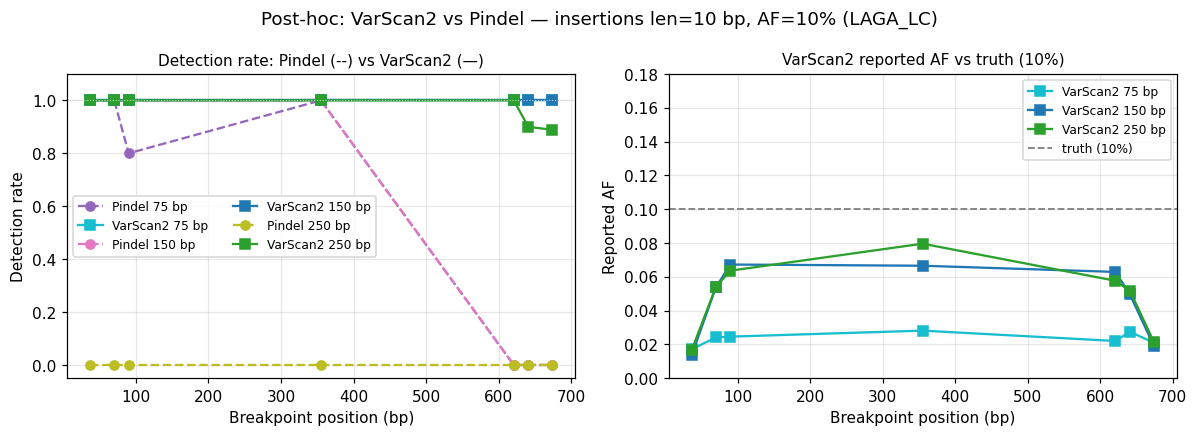

  read_len    VarScan2 mean AF   bias vs truth 10%
        75              0.0235                -76%
       150              0.0473                -53%
       250              0.0500                -50%


In [32]:
if not B_lc["ready"]:
    print("Exp B / LAGA_LC not ready — skipping VarScan2 comparison.")
else:
    _POS_LC = "amplicon_pos" if "amplicon_pos" in B_lc["mut"].columns else "indel_pos"

    _cache_lc = BENCH / "exptB" / "LAGA_LC" / "results" / "_varscan_ins_cache.csv"
    if _cache_lc.exists():
        vs_lc = pd.read_csv(_cache_lc)
        print(f"Loaded {len(vs_lc)} cached VarScan2 rows (LAGA_LC).")
    else:
        _cond_root_lc = BENCH / "exptB" / "LAGA_LC" / "conditions"
        _ins_lc = B_lc["mut"][B_lc["mut"]["indel_type"] == "ins"].copy()
        print(f"Running VarScan2 on {len(_ins_lc)} insertion conditions for LAGA_LC...")
        _rows_lc = []
        for i, (_, row) in enumerate(_ins_lc.iterrows()):
            cid = row["condition_id"]
            mp = _cond_root_lc / cid / f"{cid}.mpileup"
            if not mp.exists():
                continue
            vs_det, vs_af = _varscan_call(mp)
            _rows_lc.append({
                _POS_LC: row[_POS_LC], "read_len": int(row["read_len"]),
                "seed": int(row["seed"]),
                "pindel_detected": float(row["detected"]),
                "varscan_detected": float(vs_det),
                "varscan_af": vs_af,
            })
            if (i + 1) % 20 == 0:
                print(f"  {i+1}/{len(_ins_lc)} done")
        vs_lc = pd.DataFrame(_rows_lc)
        vs_lc.to_csv(_cache_lc, index=False)
        print(f"Done — cached to {_cache_lc.name}")

    # ── plots ─────────────────────────────────────────────────────────────────
    _RL_COLORS_LC = {75: ("#9467bd", "#17becf"), 150: ("#e377c2", "#1f77b4"),
                     250: ("#bcbd22", "#2ca02c")}
    _det_lc = vs_lc.groupby([_POS_LC, "read_len"])[["pindel_detected", "varscan_detected"]].mean().reset_index()
    _af_lc  = vs_lc.groupby([_POS_LC, "read_len"])["varscan_af"].mean().reset_index()

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
    for rl, g in _det_lc.groupby("read_len"):
        g = g.sort_values(_POS_LC)
        pcol, vcol = _RL_COLORS_LC.get(int(rl), ("gray", "gray"))
        ax1.plot(g[_POS_LC], g["pindel_detected"], "--o", color=pcol, label=f"Pindel {rl} bp")
        ax1.plot(g[_POS_LC], g["varscan_detected"], "-s",  color=vcol, label=f"VarScan2 {rl} bp")
    ax1.axhline(1, color="lightgray", lw=0.7, ls=":")
    ax1.set_ylim(-0.05, 1.10)
    ax1.set_xlabel("Breakpoint position (bp)")
    ax1.set_ylabel("Detection rate")
    ax1.set_title("Detection rate: Pindel (--) vs VarScan2 (—)")
    ax1.legend(fontsize=8, ncol=2)
    ax1.grid(alpha=0.3)

    for rl, g in _af_lc.groupby("read_len"):
        g = g.sort_values(_POS_LC)
        _, vcol = _RL_COLORS_LC.get(int(rl), ("gray", "gray"))
        ax2.plot(g[_POS_LC], g["varscan_af"], "-s", color=vcol, label=f"VarScan2 {rl} bp")
    ax2.axhline(0.10, color="gray", lw=1.2, ls="--", label="truth (10%)")
    ax2.set_ylim(0, 0.18)
    ax2.set_xlabel("Breakpoint position (bp)")
    ax2.set_ylabel("Reported AF")
    ax2.set_title("VarScan2 reported AF vs truth (10%)")
    ax2.legend(fontsize=8)
    ax2.grid(alpha=0.3)

    fig.suptitle("Post-hoc: VarScan2 vs Pindel — insertions len=10 bp, AF=10% (LAGA_LC)")
    plt.tight_layout()
    plt.show()

    print(f"{'read_len':>10}  {'VarScan2 mean AF':>18}  {'bias vs truth 10%':>18}")
    for rl, af in vs_lc.groupby("read_len")["varscan_af"].mean().items():
        print(f"{rl:>10}  {af:>18.4f}  {(af - 0.10)/0.10*100:>+17.0f}%")